# Devoir maison 2 — carnets J3 et J4

> **À rendre avant la séance 5** — comme tout devoir, avant la première séance de la semaine
> suivante. Ce devoir porte sur **J3** (comparer sans se mentir, puis ce qu’on fait des défauts
> trouvés) et sur **J4** (la mesure, et la révélation). Il se fait **seul**, à la maison, et il se
> rend.

**Ce qu’on rend :** ce carnet, rempli, déposé dans votre **dépôt GitHub personnel** avec la
déclaration d’usage de l’IA (`declaration_DM2.md`). **Le journal de nettoyage** et **le tableau à
quatre colonnes** en sont les pièces principales.

**Pourquoi ce devoir :** chaque question demande une mesure que **vous** produisez — pas une
lecture. Si vous n’avez pas compris, ça se verra tout de suite ; c’est fait pour ça.

**Ce qui est lu.** Ce qui est lu ici : **les tableaux** et le code. Les tableaux : le tableau à quatre colonnes, le
journal de nettoyage, vos métriques. Le code : là où il produit un chiffre. **Ce dépôt est
relevé** : il est lu. Les **sept devoirs** comptent ensemble pour **10 % de la
note**. C'est la composante « exercices et devoirs » du cours (25 %, avec E1, E2, E3).
**Il n’y a pas d’oral sur les devoirs** : l’oral individuel, en fin de parcours, porte sur
l’ensemble de votre travail.

**Trois mots, pour être sûr :**

- **la baseline** — le modèle bête qu’il faut battre : la réponse constante, ou la règle du délai en
  place. Un score ne se lit jamais seul.
- **la barre de bruit** — de combien un score bouge tout seul ; en dessous, un écart n’est pas un
  gain.
- **le coût et le seuil** — ce que le métier paie pour chaque erreur, et le niveau de probabilité
  au-delà duquel on alerte.

---

## Comment ça marche

1. La partie **« Mise en place »** est **fournie** : exécutez-la, ne la modifiez pas. C’est elle
   qui lit les données, construit la table, mesure les baselines, la matrice et le coût — sans
   elle, aucune question ne peut tourner.
2. Chaque **question** porte sa consigne, un squelette et des **contrôles de forme**. Ils
   vérifient la forme de votre réponse : un pourcentage, une dimension, une cohérence avec
   vos autres réponses). Ils ne donnent **jamais** la réponse, et ils se taisent tant que vous
   n’avez pas écrit.
3. Une réponse se **chiffre** ou s’**écrit** — jamais « ça a marché ». **Deux** questions demandent
   d’**annoncer ce que vous attendez avant de mesurer** : c’est volontaire.
4. **Votre échantillon personnel** : dans la mise en place, remplacez `MON_IDENTIFIANT` par votre
   pseudo GitHub. Deux questions (Q9, Q10) se calculent **sur votre échantillon** : sans cela, vos
   chiffres sont ceux de tout le monde, et votre copie se recopie d’un voisin.
5. **Cœur** et **approfondissement** se rendent dans le **même dépôt**. La
   différence ne porte pas sur la note : elle dit où porter votre effort.
6. À la fin : les **trois tableaux**, puis le **dépôt**.

> **Ce qui est évalué, et ce qui se lit.** Trois objets traversent tout le cours, et on vous
> interrogera dessus — en devoir, au partiel, à l’oral. Le premier est la fonction `predict` :
> l’interface que le professeur appelle sur une table brute. Le deuxième est le **tableau d’essais** :
> ce que vous avez annoncé, essayé, mesuré. Le troisième est le **journal de nettoyage** : chaque
> décision, son choix, son effet mesuré. Ce qu’ils **retournent** est ce qu’on vous demandera de
> défendre — et votre projet s’appuiera dessus.


## Mise en place (fournie)

Exécutez cette partie **de haut en bas**, sans rien y modifier. Elle reprend la chaîne des
carnets : les données, la table, les baselines et la barre, la matrice de confusion, le
coût métier.

Les `random_state=0` sont la **graine du tirage au sort** (expliquée en
J1 §5). Le même nombre redonne le même découpage, donc la même mesure.


### Les outils


In [55]:
# les outils
# Aucun import en bloc au début : chaque module entre dans le carnet au moment de son premier
# usage. On voit ainsi à quoi il sert, au lieu de le deviner dans une liste.

# `display` : un tableau s'affiche proprement dans un carnet, et reste lisible ailleurs.
# C'est par `display` qu'on montre TOUTES les tables de ce carnet — jamais un print de texte.
try:
    from IPython.display import display
except ImportError:
    def display(x):
        print(x)


### Les données


In [56]:
import os
import pandas as pd
# où sont les fichiers — on CHERCHE `train.csv`, on ne suppose pas un chemin
# (Kaggle a déjà déplacé ses points de montage : un chemin recopié se périme, une recherche non)
def _trouver_dossier(racines):
    """Première racine contenant train.csv — en surface, puis en profondeur."""
    for racine in racines:
        if not os.path.isdir(racine):
            continue
        if os.path.exists(os.path.join(racine, "train.csv")):
            return racine
        for chemin, _, fichiers in os.walk(racine):
            if "train.csv" in fichiers:
                return chemin
    return None

DOSSIER = _trouver_dossier(["/kaggle/input", "sortie"])
assert DOSSIER, "train.csv introuvable : les données de la compétition sont-elles montées ?"


In [57]:
train = pd.read_csv(os.path.join(DOSSIER, "train.csv"), low_memory=False)
test = pd.read_csv(os.path.join(DOSSIER, "test.csv"), low_memory=False)

ID, CIBLE = "ligne_id", "patient_absent"


### La table de travail


In [58]:
A_ECARTER = [ID, "dossier_id", "patient_id", "duree_consultation", "constantes_relevees",
             "motif_absence", "date_prise", "date_rdv", "taille_cm", "date_naissance",
             "canal_prise"]

def matrice(cols):
    """La table de travail : colonnes écartées retirées, catégorielles déclarées."""
    X = cols.drop(columns=[c for c in A_ECARTER + [CIBLE] if c in cols.columns]).copy()
    cat = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
    trop_fin = [c for c in cat if X[c].nunique() > 255]
    X = X.drop(columns=trop_fin)
    cat = [c for c in cat if c not in trop_fin]
    for c in cat:
        X[c] = X[c].fillna("").astype("category")
    return X, cat, trop_fin

X, CAT, TROP_FIN = matrice(train)
Xt, _, _ = matrice(test)

for c in CAT:
    Xt[c] = Xt[c].cat.set_categories(X[c].cat.categories)


### La cible, et la référence


In [59]:
repartition = pd.DataFrame({"lignes": [len(train), int(train[CIBLE].sum())],
                            "part (%)": [100.0, round(100 * train[CIBLE].mean(), 2)]},
                           index=["toutes", "absents"])

reference = 100 * max(train[CIBLE].mean(), 1 - train[CIBLE].mean())


In [60]:
# `y` entre ici ; la référence a déjà été calculée avec la distribution ci-dessus —
y = train[CIBLE]


### Le découpage, le modèle, et les baselines


In [61]:
# les baselines, sur le même jeu de validation — et la barre qui décide
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

Xtr, Xval, ytr, yval = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)

# 1) la réponse constante : le concurrent le plus bête, et le plus dur à battre
constante = 100 * max(yval.mean(), 1 - yval.mean())

# 2) la règle du délai : « j'annonce une absence si le délai dépasse N jours ».
#    N se choisit sur les lignes d'apprentissage, pas sur celles de contrôle.
delai_max = int(Xtr['delai_jours'].max())
taux_par_seuil = {s: float(((Xtr['delai_jours'] > s).astype(int) == ytr).mean())
                  for s in (0, 1, 3, 7, 14, 30) if s < delai_max}
seuil_appris = max(taux_par_seuil, key=taux_par_seuil.get)
regle = (Xval['delai_jours'] > seuil_appris).astype(int)

# et la règle qui ne dirait jamais rien ? c'est la réponse constante, au point près
silence = (Xval['delai_jours'] > delai_max).astype(int)

# 3) la famille linéaire : elle a besoin de nombres, on lui en prépare — la recette des
#    séances précédentes (newton-cholesky : le solveur qui converge sur cette table)
X_n = pd.get_dummies(X, columns=CAT).fillna(0)   # 0 = trou comblé ; le linéaire ne lit pas les NaN
Xtr_n, Xval_n = X_n.loc[Xtr.index], X_n.loc[Xval.index]
lineaire = LogisticRegression(solver='newton-cholesky').fit(Xtr_n, ytr)

# 4) le modèle du cours, celui des séances précédentes
modele = HistGradientBoostingClassifier(random_state=0).fit(Xtr, ytr)

# la barre : l'erreur-type de l'exactitude sur CE jeu de validation
barre = 100 * ((constante / 100) * (1 - constante / 100) / len(yval)) ** 0.5

baselines = pd.DataFrame([
    {'baseline': 'toujours présent',
     'exactitude (%)': round(constante, 2)},
    {'baseline': f'règle du délai — absent si le délai dépasse {seuil_appris} j',
     'exactitude (%)': round(100 * (regle == yval).mean(), 2)},
    {'baseline': 'absent si ce patient a déjà manqué un rendez-vous',
     'exactitude (%)': round(100 * ((Xval['taux_absence_passe'] > 0).astype(int) == yval).mean(), 2)},
    {'baseline': 'la famille linéaire',
     'exactitude (%)': round(100 * lineaire.score(Xval_n, yval), 2)},
    {'baseline': 'le modèle du cours',
     'exactitude (%)': round(100 * modele.score(Xval, yval), 2)},
])

ecart = 100 * modele.score(Xval, yval) - constante


### La matrice de confusion, et les probabilités


In [62]:
# les quatre cases, comptées à la main sur le jeu de contrôle
predit = modele.predict(Xval)

VP = int(((predit == 1) & (yval == 1)).sum())   # annoncé absent, et absent
FP = int(((predit == 1) & (yval == 0)).sum())   # annoncé absent, et venu : la fausse alerte
FN = int(((predit == 0) & (yval == 1)).sum())   # annoncé présent, et absent : l’absence manquée
VN = int(((predit == 0) & (yval == 0)).sum())   # annoncé présent, et venu

assert VP + FP + FN + VN == len(yval)

# et la probabilité, qui servira à déplacer le seuil : c’est elle qui décide, pas le 0/1
probabilites = modele.predict_proba(Xval)[:, 1]

# les quatre mêmes cases, retrouvées par la bibliothèque — le contrôle, pas la confiance
from sklearn.metrics import confusion_matrix
confirme = confusion_matrix(yval, predit).ravel()          # ordre : VN, FP, FN, VP
assert (VN, FP, FN, VP) == tuple(int(v) for v in confirme), 'les quatre cases ne concordent pas'


### Le coût métier


In [63]:
# le coût d’une décision, et la dérivation du seuil
COUT_FP, COUT_FN = 25, 100   # les deux montants de l’énoncé, en unités de coût

def cout(decision, verite=yval):
    faux_positifs = int(((decision == 1) & (verite == 0)).sum())
    faux_negatifs = int(((decision == 0) & (verite == 1)).sum())
    return COUT_FP * faux_positifs + COUT_FN * faux_negatifs

seuil_theorique = COUT_FP / (COUT_FP + COUT_FN)


### Les outils du nettoyage


In [64]:
# un trou aléatoire : cinq traitements, et ce que chacun change
def score_de(Xe, ye=None):
    """Entraîne et mesure, toujours sur la même découpe."""
    ye = y if ye is None else ye
    Xtr_m, Xval_m, ytr_m, yval_m = train_test_split(Xe, ye, test_size=0.2, stratify=ye, random_state=0)
    return 100 * HistGradientBoostingClassifier(random_state=0).fit(Xtr_m, ytr_m).score(Xval_m, yval_m)

# le même découpage, les lignes retirées seulement côté apprentissage : le jeu de contrôle
# ne change pas, donc les deux scores se comparent vraiment — ce que `score_de` ne fait pas
def score_sans_lignes(masque):
    """Retire des lignes du seul côté apprentissage, et mesure sur le même jeu de contrôle."""
    garde = masque.loc[Xtr.index]
    return 100 * HistGradientBoostingClassifier(random_state=0).fit(
        Xtr[garde], ytr[garde]).score(Xval, yval)


In [65]:
# les colonnes inutiles, et la raison de chacune
raisons = {
    "zone_clinique": "une seule valeur sur toute la table",
    "indice_meteo_jour": "du bruit pur",
    "score_territorial": "42 052 valeurs, aucune raison de croire qu’elles disent quelque chose",
    "age_mois": "age_mois ÷ 12 = age — sur 100 % des lignes (mesuré en J1, 2.6)",
    "cout_acte": "montant_acte = 13,68 × cout_acte, rapport constant (mesuré en J1, 2.6)",
}
inutiles = [c for c in raisons if c in X.columns]


In [66]:
# le journal de nettoyage — ce qui est lu n’est pas le score, c’est le tableau
JOURNAL = []

def journal(decision, choix, raison, effet):
    """Une décision, le choix fait, la raison qu’on donnerait à un audit, et l’effet mesuré
       en points — avec la comparaison au double de la barre, qui dit si l’effet compte."""
    JOURNAL.append({"décision": decision, "choix": choix, "raison (sans le score)": raison,
                    "effet mesuré": round(effet, 2),
                    "> double de la barre ?": "oui" if abs(effet) > 2 * barre else "non"})
    display(pd.DataFrame(JOURNAL))


### Le pipeline, et le fichier à envoyer


In [67]:
# le pipeline : de la table brute à la prédiction, en un seul endroit
# Même contrat que `predict` : une table brute entre, un 0/1 par ligne sort.
def nettoyer(brut):
    """Les décisions apprises sur la table d’apprentissage, appliquées à une table brute :
       colonnes inutiles écartées, colonnes trop fines écartées, et les catégories de
       l’apprentissage — jamais recalculées sur la table qu’on reçoit."""
    d = matrice(brut)[0]
    d = d.drop(columns=[c for c in inutiles if c in d.columns])
    d = d[[c for c in X.columns if c in d.columns]]
    for c in CAT:
        if c not in d.columns:
            continue
        d[c] = d[c].astype("category").cat.set_categories(X[c].cat.categories)
    return d

def pipeline(brut):
    """Reçoit une table brute et rend un tableau de 0/1 — la chaîne complète."""
    return modele_final.predict(nettoyer(brut)).astype(int)

X_propre = nettoyer(train)
modele_final = HistGradientBoostingClassifier(random_state=0).fit(X_propre, y)

soumission = pd.DataFrame({ID: test[ID], CIBLE: pipeline(test)})
soumission.to_csv("submission.csv", index=False)


### Le rituel : annoncer avant de mesurer


In [68]:
# l'horloge entre ici : c'est elle qui rend une prédiction vérifiable
from datetime import datetime

ESSAIS = []
PREDICTIONS = []

def prevoir(essai, attendu, raison):
    """Écrit ce que vous attendez AVANT de mesurer — horodaté.
       `noter(...)` refuse ensuite tout essai sans prédiction : l'ordre n'est pas demandé, il est
       appliqué. Ce que cette fonction garantit, exactement : une prédiction EXISTAIT avant que la
       ligne du tableau soit écrite. Elle ne date pas la mesure — le score lui arrive déjà calculé.
       Pour la garantie complète, mesurez dans `essai(...)`, qui date la mesure lui-même."""
    PREDICTIONS[:] = [p for p in PREDICTIONS if p["essai"] != essai]
    PREDICTIONS.append({"essai": essai, "attendu": attendu, "raison": raison,
                        "écrit à": datetime.now().strftime("%H:%M:%S")})
    display(pd.DataFrame(PREDICTIONS))

def essai(nom, mesure, changement="", attendu=""):
    """Le chemin STRICT : la mesure est prise ICI, donc l'ordre (prédiction puis mesure) est prouvé.
       `mesure` est une fonction sans argument qui rend le score, par exemple
       `lambda: modele.score(Xval, yval)`. Refuse de mesurer sans prédiction."""
    prevu = [p for p in PREDICTIONS if p["essai"] == nom]
    if not prevu:
        print(f"refusé : aucune prédiction pour « {nom} ». Écrivez prevoir(...) d'abord.")
        return None
    score = 100 * mesure()
    noter(nom, changement or "voir la question", attendu or prevu[0]["attendu"], score)
    return score

def noter(hypothese, changement, attendu, score):
    """Ajoute une ligne au tableau. `attendu` : un signe et une raison, jamais une valeur.
       Ré-exécuter une cellule REMPLACE la ligne de même `hypothèse` : elle ne la double pas.

       REFUSE d'enregistrer un essai non annoncé — c'est la règle du cours, appliquée.
       Ce qu'elle garantit, et rien de plus : une prédiction existait AVANT que cette ligne soit
       écrite. Elle ne date pas la mesure — d'où `essai(...)` pour la garantie complète."""
    prevu = [p for p in PREDICTIONS if p["essai"] == hypothese]
    if not prevu:
        print(f"  refusé : aucune prédiction pour « {hypothese} ».")
        print("  Écrivez prevoir(...) d'abord — l'ordre est vérifié, pas seulement demandé.")
        return
    ligne = {"hypothèse": hypothese, "changement": changement,
             "attendu": attendu, "mesuré": round(score, 2),
             "prédiction écrite avant ?": "oui, à " + prevu[0]["écrit à"]}
    ESSAIS[:] = [e for e in ESSAIS if e["hypothèse"] != hypothese] + [ligne]
    display(pd.DataFrame(ESSAIS))


### Votre échantillon personnel — **à personnaliser**

Deux questions se calculent sur un **échantillon qui n’appartient qu’à vous** : il est tiré de
votre identifiant. Il fait la moitié du jeu de contrôle. Remplacez la ligne `MON_IDENTIFIANT`
par votre pseudo GitHub, puis exécutez la cellule : elle affiche la taille de votre échantillon et
sa graine. Le reste de la mise en place, lui, ne se modifie pas.


In [69]:
# ── votre échantillon personnel : il ne change que les chiffres que vous devez produire
import zlib

MON_IDENTIFIANT = "Shiro26-rg"
graine_perso = zlib.crc32(MON_IDENTIFIANT.strip().lower().encode())
positions = Xval.sample(frac=0.5, random_state=graine_perso).index
ou = Xval.index.get_indexer(positions)
Xval_perso, yval_perso, proba_perso = Xval.loc[positions], yval.loc[positions], probabilites[ou]

print(f"votre échantillon personnel : {len(positions)} lignes (la moitié du jeu de contrôle), graine {graine_perso}")
if "remplacez" in MON_IDENTIFIANT:
    print("  ⚠ remplacez MON_IDENTIFIANT par votre pseudo : sinon votre échantillon est celui de tout le monde.")


votre échantillon personnel : 14990 lignes (la moitié du jeu de contrôle), graine 2757084395


### Les vérifications, et le tableau d’essais


In [70]:
def phrases(reponse):
    """Une réponse de prose peut arriver en liste, en Series ou en table : on la ramène à des phrases."""
    if hasattr(reponse, "to_dict"):
        return [str(v) for ligne in reponse.to_dict("records") for v in ligne.values()]
    return [str(p) for p in reponse]

VERIFICATIONS = []

def verifier(nom, condition, indice=''):
    """Contrôle silencieux : il ne dit jamais la valeur attendue."""
    VERIFICATIONS.append({'contrôle': nom, 'tient': bool(condition)})
    print(('  ok        ' if condition else '  À REVOIR  ') + nom
          + ('' if condition else '   ->   ' + indice))

def controle(nom, quoi, indice=''):
    """Contrôle de forme, posé dans la cellule de la question. Il ne compare jamais à une valeur
       attendue : un type, une plage, une dimension, ou une cohérence avec vos autres réponses.
       Tant que la réponse n’est pas écrite, il se tait."""
    try:
        ok = bool(quoi())
    except NameError:
        print(f'  (pas encore écrit)  {nom}')
        return
    except Exception as e:
        print(f'  REVOIR    {nom}   ->   {type(e).__name__} : {e}')
        return
    VERIFICATIONS.append({'contrôle': nom, 'tient': ok})
    print(('  ok        ' if ok else '  REVOIR    ') + nom + ('' if ok else '   ->   ' + indice))

# le tableau d'essais et son `noter` strict viennent de la mise en place (extraits de J1) :
# il refuse un essai non annoncé. Le devoir n'en redéfinit pas un second, plus permissif.


### La mise en place est-elle prête ?


In [71]:
# sept vérifications d'état — elles portent sur la mise en place, pas sur vos réponses
verifier('les données sont chargées', len(train) > 100_000)
verifier('la table de travail est construite', 'patient_absent' not in X.columns)
verifier('le découpage est fait, le modèle ajusté', len(probabilites) == len(yval))
verifier('les baselines sont mesurées', constante > 50 and barre > 0)
verifier('votre échantillon personnel est prêt', len(yval_perso) > 1000)
verifier('le pipeline tourne sur une table brute', len(pipeline(test.head(50))) == 50)
verifier('le fichier est écrit', os.path.exists('submission.csv'))


  ok        les données sont chargées
  ok        la table de travail est construite
  ok        le découpage est fait, le modèle ajusté
  ok        les baselines sont mesurées
  ok        votre échantillon personnel est prêt
  ok        le pipeline tourne sur une table brute
  ok        le fichier est écrit


## Les questions

**Douze questions : dix de cœur, deux d’approfondissement.** Elles suivent l’ordre des
carnets — J3 d’abord (comparer, puis nettoyer), J4 ensuite (la mesure). Pour chacune : lisez
la consigne, écrivez votre code (ou votre phrase) à l’emplacement prévu, et **exécutez la
cellule** — c’est l’exécution qui déclenche les contrôles.


### Question 1 — Une baseline de votre main, et sa place dans le tableau  ·  *carnet J3*  ·  *cœur*


**Contexte.** Le carnet J3 a mesuré **ses** baselines. La vôtre doit être la vôtre.

**Consigne.**
  1. choisissez une colonne que **ni la réponse constante ni la règle du délai du carnet**
     (`delai_jours`) n'utilise. Écrivez la règle en une phrase : quel signal, quelle décision ;
  2. mesurez son exactitude sur le jeu de validation (`Xval`, `yval`) ;
  3. divisez son écart à `constante` — la réponse constante, **81,75 %** — par `barre` : combien
     d'erreurs-types cela fait-il ?

**Livrables.** `ma_regle` · `ma_baseline` · `mes_erreurs_types`.

**Critère de réussite.** Une règle qui **égale ou dépasse** la constante est un résultat — dites-le.
Un écart sous une barre n'est pas un gain.

*≈ 20 min.*


In [72]:
# Ma baseline : une règle sur l'âge — ni la réponse constante, ni le délai, ni la règle « a déjà manqué un rendez-vous ».
# Comme le carnet le fait pour le délai, la tranche d'âge est choisie sur les lignes d'APPRENTISSAGE,
# puis mesurée sur la validation.
candidats_age = {
    "age < 18": lambda d: d['age'].between(0, 17),
    "age < 25": lambda d: d['age'].between(0, 24),
    "age >= 65": lambda d: d['age'] >= 65,
    "age >= 75": lambda d: d['age'] >= 75,
    "age >= 85": lambda d: d['age'] >= 85,
}
exactitude_apprentissage = {nom: float((regle_age(Xtr).astype(int) == ytr).mean())
                            for nom, regle_age in candidats_age.items()}
meilleure_regle = max(exactitude_apprentissage, key=exactitude_apprentissage.get)

ma_regle = (f"J'annonce une absence si {meilleure_regle} : cette tranche d'âge est choisie parmi cinq candidates "
            "sur les lignes d'apprentissage (signal : l'âge ; décision : absent), puis mesurée sur la validation.")
masque_apprentissage = candidats_age[meilleure_regle](Xtr)
decision_age = candidats_age[meilleure_regle](Xval).astype(int)
ma_baseline = round(100 * (decision_age == yval).mean(), 2)
mes_erreurs_types = (ma_baseline - constante) / barre

print(f"Règle « {meilleure_regle} » ({int(decision_age.sum())} patients annoncés absents sur {len(yval)}) : "
      f"{ma_baseline:.2f} % ; écart à la réponse constante : {ma_baseline - constante:+.2f} point, "
      f"soit {mes_erreurs_types:+.2f} barre(s).")
if masque_apprentissage.sum() > 0:
    taux_tranche = 100 * ytr[masque_apprentissage].mean()
    print(f"Taux d'absence réel de cette tranche (apprentissage) : {taux_tranche:.1f} %. "
          + ("Il dépasse 50 % : annoncer « absent » pour toute la tranche évite plus d'erreurs qu'elle n'en crée."
             if taux_tranche > 50 else
             "Il reste sous 50 % : annoncer « absent » pour toute la tranche fait plus d'erreurs qu'elle n'en évite."))
if abs(mes_erreurs_types) < 1:
    print("Conclusion : l'écart est inférieur à une barre de bruit ; ce n'est pas un gain mesurable.")
elif mes_erreurs_types > 0:
    print("Conclusion : la règle dépasse la réponse constante, avec un écart supérieur à une barre.")
else:
    print("Conclusion : la règle est moins exacte que la réponse constante, d'au moins une barre de bruit : ce n'est pas une baseline à retenir.")

controle('la règle est écrite', lambda: len(ma_regle) > 40,
         'décrivez la colonne et la décision en une phrase')
controle('une exactitude en pourcentage', lambda: 0 < ma_baseline <= 100,
         'un pourcentage (0 à 100), pas une proportion')
controle('un écart exprimé en erreurs-types', lambda: 0 <= abs(mes_erreurs_types) < 30,
         'divisez votre écart par la barre')

Règle « age >= 85 » (678 patients annoncés absents sur 29979) : 80.33 % ; écart à la réponse constante : -1.42 point, soit -6.37 barre(s).
Taux d'absence réel de cette tranche (apprentissage) : 18.0 %. Il reste sous 50 % : annoncer « absent » pour toute la tranche fait plus d'erreurs qu'elle n'en évite.
Conclusion : la règle est moins exacte que la réponse constante, d'au moins une barre de bruit : ce n'est pas une baseline à retenir.
  ok        la règle est écrite
  ok        une exactitude en pourcentage
  ok        un écart exprimé en erreurs-types


### Question 2 — Le classement affiché tient-il ?  ·  *carnet J3*  ·  *cœur*


**Contexte.** En J3, douze variantes jugées sur 1 000 lignes affichées ne se retrouvaient pas sur
celles jamais montrées. L'**affichage** est l'échantillon sur lequel le classement se lit ; le reste, celui qu'on
ne regarde pas avant de mesurer.

**Consigne.**
  1. annoncez **avant** de mesurer : le premier de l’affichage sera-t-il aussi le premier des lignes jamais montrées ?
  2. pour cette question, mettez **4 000 lignes de côté dans `Xtr`, avant d’entraîner** : elles ne servent ni à
     l’apprentissage, ni au choix des réglages. Coupez-les en 1 000 pour l’affichage et 3 000 jamais
     montrées (`train_test_split`, `random_state=0`) ;
  3. faites varier **six** réglages de votre choix, chacun entraîné sur les lignes qui restent — et dites **ce qui varie** (le nombre
     d'itérations ? la profondeur ? les deux ?) ;
  4. mesurez. Le premier de l’affichage est la variante qui a le meilleur score sur les 1 000.
     Donnez son **rang** parmi les lignes jamais montrées (1 = premier).

**Livrables.** `mon_annonce` · `score_affiche_premier` · `score_jamais_montre_premier` · `rang_jamais_montre_premier`.

**Critère de réussite.** Un seul tirage ne prouve pas qu'« un classement tient » : il montre **ce**
tirage-là. Dites ce que vous pouvez conclure, et ce que vous ne pouvez pas.

*≈ 25 min.*


In [73]:
# L'annonce personnelle est écrite avant tout entraînement et toute mesure de cette question.
mon_annonce = "Je prévois que le meilleur réglage sur les 1 000 lignes affichées ne restera probablement pas premier sur les 3 000 lignes cachées, car le classement peut dépendre du tirage de l'échantillon."
attendu_q2 = mon_annonce
X_apprentissage_q2, X_decoupe_q2, y_apprentissage_q2, y_decoupe_q2 = train_test_split(
    Xtr, ytr, test_size=4000, stratify=ytr, random_state=0)
X_affiche_q2, X_jamais_q2, y_affiche_q2, y_jamais_q2 = train_test_split(
    X_decoupe_q2, y_decoupe_q2, test_size=0.75, stratify=y_decoupe_q2, random_state=0)
reglages_q2 = [
    (20, 7), (40, 7), (60, 7), (20, 15), (40, 15), (60, 15)
]
noms_q2 = [f"Q2 · max_iter={iterations}, max_leaf_nodes={feuilles}"
           for iterations, feuilles in reglages_q2]
for nom in noms_q2:
    prevoir(nom, attendu_q2,
            "La taille et le tirage de l'échantillon d'affichage peuvent modifier l'ordre des variantes.")

scores_affiche_q2, scores_jamais_q2 = [], []
for nom, (iterations, feuilles) in zip(noms_q2, reglages_q2):
    candidat = HistGradientBoostingClassifier(max_iter=iterations, max_leaf_nodes=feuilles,
                                                early_stopping=False, random_state=0)
    candidat.fit(X_apprentissage_q2, y_apprentissage_q2)
    scores_affiche_q2.append(essai(
        nom, lambda m=candidat: m.score(X_affiche_q2, y_affiche_q2),
        changement=f"max_iter={iterations}, max_leaf_nodes={feuilles}",
        attendu=attendu_q2))
    scores_jamais_q2.append(100 * candidat.score(X_jamais_q2, y_jamais_q2))

premier_affiche_q2 = max(range(6), key=lambda i: scores_affiche_q2[i])
score_affiche_premier = round(scores_affiche_q2[premier_affiche_q2], 2)
score_jamais_montre_premier = round(scores_jamais_q2[premier_affiche_q2], 2)
rang_jamais_montre_premier = 1 + sum(
    score > scores_jamais_q2[premier_affiche_q2] for score in scores_jamais_q2)
tableau_q2 = pd.DataFrame({
    "réglage": noms_q2,
    "affichage (%)": [round(s, 2) for s in scores_affiche_q2],
    "jamais montré (%)": [round(s, 2) for s in scores_jamais_q2],
})
display(tableau_q2)
meilleur_affiche_q2 = max(scores_affiche_q2)
ex_aequo_q2 = [i for i, s in enumerate(scores_affiche_q2) if s == meilleur_affiche_q2]
rangs_ex_aequo_q2 = [1 + sum(s > scores_jamais_q2[i] for s in scores_jamais_q2) for i in ex_aequo_q2]
barre_affichage_q2 = 100 * ((meilleur_affiche_q2 / 100) * (1 - meilleur_affiche_q2 / 100) / len(y_affiche_q2)) ** 0.5
print(f"Réglages variés : max_iter et max_leaf_nodes. Le premier affiché est {noms_q2[premier_affiche_q2]} ; son score caché est {score_jamais_montre_premier:.2f} % et son rang caché {rang_jamais_montre_premier}/6.")
if len(ex_aequo_q2) > 1:
    print(f"Attention : {len(ex_aequo_q2)} variantes sont à égalité en tête de l'affichage ({meilleur_affiche_q2:.2f} %) ; "
          f"le « premier » est départagé par l'ordre de la liste. Parmi ces ex aequo, les rangs cachés vont de "
          f"{min(rangs_ex_aequo_q2)} à {max(rangs_ex_aequo_q2)}.")
print(f"Sur {len(y_affiche_q2)} lignes, la barre de bruit de l'affichage est d'environ {barre_affichage_q2:.2f} point : "
      f"l'écart entre le meilleur et le pire affichés ({max(scores_affiche_q2) - min(scores_affiche_q2):.2f} point) "
      + ("dépasse" if max(scores_affiche_q2) - min(scores_affiche_q2) > barre_affichage_q2 else "ne dépasse pas")
      + " cette barre.")
print("Ce tirage compare ces six variantes sur ces deux groupes ; il ne prouve pas qu'un classement tient sur d'autres échantillons.")

controle('une annonce est écrite avant la mesure', lambda: len(mon_annonce) > 30,
         'annoncez ce que vous attendez, en une phrase')
controle('deux scores en pourcentage',
         lambda: 50 < score_affiche_premier <= 100 and 50 < score_jamais_montre_premier <= 100,
         'deux pourcentages, un par jeu')
controle('un rang entre 1 et 6', lambda: 1 <= rang_jamais_montre_premier <= 6,
         'votre premier de l’affichage est l’un de vos six : donnez son rang parmi les lignes jamais montrées')

,essai,attendu,raison,écrit à
0,"Q2 · max_iter=20, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36


,essai,attendu,raison,écrit à
0,"Q2 · max_iter=20, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
1,"Q2 · max_iter=40, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36


,essai,attendu,raison,écrit à
0,"Q2 · max_iter=20, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
1,"Q2 · max_iter=40, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
2,"Q2 · max_iter=60, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36


,essai,attendu,raison,écrit à
0,"Q2 · max_iter=20, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
1,"Q2 · max_iter=40, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
2,"Q2 · max_iter=60, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
3,"Q2 · max_iter=20, max_leaf_nodes=15",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36


,essai,attendu,raison,écrit à
0,"Q2 · max_iter=20, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
1,"Q2 · max_iter=40, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
2,"Q2 · max_iter=60, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
3,"Q2 · max_iter=20, max_leaf_nodes=15",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
4,"Q2 · max_iter=40, max_leaf_nodes=15",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36


,essai,attendu,raison,écrit à
0,"Q2 · max_iter=20, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
1,"Q2 · max_iter=40, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
2,"Q2 · max_iter=60, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
3,"Q2 · max_iter=20, max_leaf_nodes=15",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
4,"Q2 · max_iter=40, max_leaf_nodes=15",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
5,"Q2 · max_iter=60, max_leaf_nodes=15",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36


... (4 outputs left out)

,hypothèse,changement,attendu,mesuré,prédiction écrite avant ?
0,"Q2 · max_iter=20, max_leaf_nodes=7","max_iter=20, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,83.2,"oui, à 22:33:36"
1,"Q2 · max_iter=40, max_leaf_nodes=7","max_iter=40, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,83.2,"oui, à 22:33:36"
2,"Q2 · max_iter=60, max_leaf_nodes=7","max_iter=60, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,83.2,"oui, à 22:33:36"
3,"Q2 · max_iter=20, max_leaf_nodes=15","max_iter=20, max_leaf_nodes=15",Je prévois que le meilleur réglage sur les 1 0...,83.0,"oui, à 22:33:36"
4,"Q2 · max_iter=40, max_leaf_nodes=15","max_iter=40, max_leaf_nodes=15",Je prévois que le meilleur réglage sur les 1 0...,82.9,"oui, à 22:33:36"


,hypothèse,changement,attendu,mesuré,prédiction écrite avant ?
0,"Q2 · max_iter=20, max_leaf_nodes=7","max_iter=20, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,83.2,"oui, à 22:33:36"
1,"Q2 · max_iter=40, max_leaf_nodes=7","max_iter=40, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,83.2,"oui, à 22:33:36"
2,"Q2 · max_iter=60, max_leaf_nodes=7","max_iter=60, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,83.2,"oui, à 22:33:36"
3,"Q2 · max_iter=20, max_leaf_nodes=15","max_iter=20, max_leaf_nodes=15",Je prévois que le meilleur réglage sur les 1 0...,83.0,"oui, à 22:33:36"
4,"Q2 · max_iter=40, max_leaf_nodes=15","max_iter=40, max_leaf_nodes=15",Je prévois que le meilleur réglage sur les 1 0...,82.9,"oui, à 22:33:36"
5,"Q2 · max_iter=60, max_leaf_nodes=15","max_iter=60, max_leaf_nodes=15",Je prévois que le meilleur réglage sur les 1 0...,82.8,"oui, à 22:33:36"


,réglage,affichage (%),jamais montré (%)
0,"Q2 · max_iter=20, max_leaf_nodes=7",83.2,82.60
1,"Q2 · max_iter=40, max_leaf_nodes=7",83.2,82.67
2,"Q2 · max_iter=60, max_leaf_nodes=7",83.2,82.87
3,"Q2 · max_iter=20, max_leaf_nodes=15",83.0,82.63
4,"Q2 · max_iter=40, max_leaf_nodes=15",82.9,82.67
5,"Q2 · max_iter=60, max_leaf_nodes=15",82.8,82.63


Réglages variés : max_iter et max_leaf_nodes. Le premier affiché est Q2 · max_iter=20, max_leaf_nodes=7 ; son score caché est 82.60 % et son rang caché 6/6.
Attention : 3 variantes sont à égalité en tête de l'affichage (83.20 %) ; le « premier » est départagé par l'ordre de la liste. Parmi ces ex aequo, les rangs cachés vont de 1 à 6.
Sur 1000 lignes, la barre de bruit de l'affichage est d'environ 1.18 point : l'écart entre le meilleur et le pire affichés (0.40 point) ne dépasse pas cette barre.
Ce tirage compare ces six variantes sur ces deux groupes ; il ne prouve pas qu'un classement tient sur d'autres échantillons.
  ok        une annonce est écrite avant la mesure
  ok        deux scores en pourcentage
  ok        un rang entre 1 et 6


### Question 3 — Deux modèles, un seul découpage  ·  *carnet J3*  ·  *cœur*


**Contexte.** En J3, deux réglages comparés sur le même découpage différaient de **0,04 point**.

**Consigne.**
  1. entraînez **deux modèles de votre choix** sur `Xtr` — deux familles, ou deux réglages
     réellement différents. Attention : deux `max_iter` du même modèle boosté peuvent s'arrêter au
     **même arbre** (l'arrêt anticipé) et comparer un modèle à lui-même ;
  2. mesurez-les sur **le même** `Xval` ;
  3. écrivez l'écart en points, et dites s'il fait plus qu'**une** barre de bruit, plus que **deux**.

**Livrables.** `score_a` · `score_b` · `mon_verdict`.

**Critère de réussite.** La comparaison n'est honnête que si le découpage ne change pas entre les
deux mesures. Dites aussi, en une phrase, si les deux modèles sont vraiment deux modèles.

*≈ 20 min.*


In [74]:
# Mes deux modèles, entraînés ici sur le même Xtr et mesurés sur le même Xval.
# Deux modèles réellement différents : un boosting réglé à la main (arrêt anticipé désactivé : il va jusqu'au
# bout de ses 100 arbres, il ne peut donc pas « s'arrêter au même arbre » qu'un autre) et un arbre unique.
from sklearn.tree import DecisionTreeClassifier

mon_modele_a = HistGradientBoostingClassifier(max_iter=100, learning_rate=0.05, max_leaf_nodes=15,
                                              early_stopping=False, random_state=0).fit(Xtr, ytr)
mon_modele_b = DecisionTreeClassifier(max_depth=6, min_samples_leaf=100, random_state=0).fit(Xtr_n, ytr)

score_a = round(100 * mon_modele_a.score(Xval, yval), 2)
score_b = round(100 * mon_modele_b.score(Xval_n, yval), 2)
ecart_modeles = abs(score_a - score_b)
ecart_en_barres_q3 = ecart_modeles / barre
if ecart_modeles > 2 * barre:
    niveau_bruit = "l'écart dépasse deux barres de bruit"
elif ecart_modeles > barre:
    niveau_bruit = "l'écart dépasse une barre, mais pas deux"
else:
    niveau_bruit = "l'écart ne dépasse pas une barre de bruit"
mon_verdict = (f"Boosting réglé à la main (100 itérations, 15 feuilles) : {score_a:.2f} % ; arbre de décision unique "
               f"(profondeur 6) : {score_b:.2f} %. L'écart est de {ecart_modeles:.2f} point, soit {ecart_en_barres_q3:.1f} "
               f"barre(s) de bruit de {barre:.2f} : {niveau_bruit}. Ce sont bien deux modèles : le premier additionne "
               "100 arbres qui se corrigent, le second est un seul arbre, et aucun n'est arrêté plus tôt que prévu ; "
               "les deux sont ajustés sur le même Xtr et mesurés sur le même Xval.")
print(mon_verdict)

controle('deux scores en pourcentage',
         lambda: 50 < score_a <= 100 and 50 < score_b <= 100, 'deux pourcentages')
controle('un verdict écrit', lambda: len(mon_verdict) > 40,
         'dites si l’écart dépasse une barre, deux barres, ou aucune')

Boosting réglé à la main (100 itérations, 15 feuilles) : 82.52 % ; arbre de décision unique (profondeur 6) : 82.54 %. L'écart est de 0.02 point, soit 0.1 barre(s) de bruit de 0.22 : l'écart ne dépasse pas une barre de bruit. Ce sont bien deux modèles : le premier additionne 100 arbres qui se corrigent, le second est un seul arbre, et aucun n'est arrêté plus tôt que prévu ; les deux sont ajustés sur le même Xtr et mesurés sur le même Xval.
  ok        deux scores en pourcentage
  ok        un verdict écrit


### Question 4 — Votre tableau à quatre colonnes  ·  *carnet J3*  ·  *cœur*


**Contexte.** Le tableau à quatre colonnes du carnet J3, rempli avec **vos** lignes.

**Consigne.**
  1. construisez `mon_tableau` avec les quatre colonnes du carnet — `modèle · validation · affiché ·
     écart` — et **au moins deux** lignes de votre choix ;
  2. la colonne de l’**affichage** ne se remplit que pour un modèle **réellement envoyé**. Aucun
     envoi n’est demandé ici : reprenez le score affiché du cours (**81,81**) sur la ligne du
     modèle du cours, et laissez `None` ailleurs ;
  3. écrivez les trois phrases : *que ferais-je si je ne regardais que l’affichage ? qu'est-ce que
     cela me coûterait en vrai ? qu'est-ce qui me l'aurait dit ?*

**Livrables.** `mon_tableau` · `si_je_ne_voyais_que_l_affichage` · `ce_que_cela_couterait` ·
`ce_qui_me_l_aurait_dit`.

**Critère de réussite.** Une colonne vide n'est pas un oubli — c'est un modèle qui n'a pas été
envoyé. Un écart sain est petit ; un écart qui grandit dit que le modèle a été choisi pour plaire à l’affichage.

*≈ 20 min.*


In [75]:
# Le seul affichage fourni est celui du modèle du cours ; les autres modèles n'ont pas été envoyés.
validation_cours = round(100 * modele.score(Xval, yval), 2)
validation_constante = round(constante, 2)
validation_logistique = round(100 * lineaire.score(Xval_n, yval), 2)
affiche_cours = 81.81
mon_tableau = pd.DataFrame([
    {"modèle": "modèle du cours", "validation": validation_cours,
     "affiché": affiche_cours, "écart": round(affiche_cours - validation_cours, 2)},
    {"modèle": "réponse constante", "validation": validation_constante,
     "affiché": None, "écart": None},
    {"modèle": "régression logistique", "validation": validation_logistique,
     "affiché": None, "écart": None},
], columns=["modèle", "validation", "affiché", "écart"])

ecart_affiche = round(affiche_cours - validation_cours, 2)
ecart_affiche_barres = ecart_affiche / barre
if ecart_affiche < 0:
    lecture_signe = ("L'affichage est plus bas que la validation : rien n'indique un modèle choisi "
                     "pour plaire à l'affichage.")
else:
    lecture_signe = ("L'affichage est plus haut que la validation : cela peut signaler un modèle "
                     "choisi pour plaire à l'affichage.")

si_je_ne_voyais_que_l_affichage = (
    "Je ne lirais que la colonne « affiché » : seul le modèle du cours en a une (81,81 %), je le garderais donc, "
    "sans pouvoir le comparer à la constante ni à la logistique, qui n'ont pas été envoyées.")
ce_que_cela_couterait = (
    f"L'écart affiché moins validation vaut {ecart_affiche:+.2f} point ({ecart_affiche_barres:+.1f} barre(s) de bruit). "
    f"{lecture_signe} Mais choisir sur l'affichage, c'est classer par exactitude : or une absence manquée coûte "
    "100 et une fausse alerte 25 (Q11), et le modèle le plus exact n'est pas celui qui coûte le moins cher.")
petit_ou_grand = "inférieur à un point" if abs(ecart_affiche) < 1 else "d'au moins un point"
ce_qui_me_l_aurait_dit = (
    f"La colonne « écart » de ce tableau, lue avec la barre de bruit de {barre:.2f} point : {abs(ecart_affiche_barres):.1f} "
    f"barre(s) ici. L'affichage vient d'un autre échantillon, avec son propre bruit ; l'écart est {petit_ou_grand}, "
    "et un écart sain est petit.")
display(mon_tableau)
print(si_je_ne_voyais_que_l_affichage)
print(ce_que_cela_couterait)
print(ce_qui_me_l_aurait_dit)

controle('un tableau d’au moins deux modèles',
         lambda: len(mon_tableau) >= 2, 'deux lignes au moins')
controle('les trois phrases sont écrites',
         lambda: min(len(si_je_ne_voyais_que_l_affichage),
                     len(ce_que_cela_couterait), len(ce_qui_me_l_aurait_dit)) > 40,
         'trois phrases, chacune complète')

,modèle,validation,affiché,écart
0,modèle du cours,82.51,81.81,-0.7
1,réponse constante,81.75,NaN,NaN
2,régression logistique,82.21,NaN,NaN


Je ne lirais que la colonne « affiché » : seul le modèle du cours en a une (81,81 %), je le garderais donc, sans pouvoir le comparer à la constante ni à la logistique, qui n'ont pas été envoyées.
L'écart affiché moins validation vaut -0.70 point (-3.1 barre(s) de bruit). L'affichage est plus bas que la validation : rien n'indique un modèle choisi pour plaire à l'affichage. Mais choisir sur l'affichage, c'est classer par exactitude : or une absence manquée coûte 100 et une fausse alerte 25 (Q11), et le modèle le plus exact n'est pas celui qui coûte le moins cher.
La colonne « écart » de ce tableau, lue avec la barre de bruit de 0.22 point : 3.1 barre(s) ici. L'affichage vient d'un autre échantillon, avec son propre bruit ; l'écart est inférieur à un point, et un écart sain est petit.
  ok        un tableau d’au moins deux modèles
  ok        les trois phrases sont écrites


### Question 5 — Le plafond : trois familles  ·  *carnet J3*  ·  *cœur*


**Contexte.** Trois familles qui ne partagent pas leur mécanisme plafonnent au même endroit : le
plafond n'est alors pas dans le modèle.

**Consigne.**
  1. annoncez **avant** : trois familles très différentes donneront-elles des scores très
     différents ?
  2. mesurez **trois familles **différentes** de votre choix** sur la même table, et le même découpage ;
  3. dites de combien de points la meilleure dépasse la moins bonne. Puis ce que cela implique :
     le plafond est-il dans le modèle, ou dans les données — **en exactitude** ?

**Livrables.** `mon_annonce_plafond` · `trois_scores` · `ma_conclusion_plafond`.

**Critère de réussite.** Toute conclusion doit venir avec l'écart **chiffré** entre la meilleure et la moins bonne — sinon c'est une impression.

*≈ 15 min.*


In [76]:
# Prévision personnelle écrite avant l'entraînement et la comparaison des trois familles.
mon_annonce_plafond = "Je prévois que les trois familles auront des exactitudes assez proches, car elles apprennent sur les mêmes données et peuvent être limitées par les mêmes informations disponibles ; je comparerai l'écart mesuré."
noms_familles_q5 = ["HistGradientBoosting", "LogisticRegression", "RandomForest"]
attendu_q5 = mon_annonce_plafond
for nom in noms_familles_q5:
    prevoir(f"Q5 · {nom}", attendu_q5,
            "Comparer trois mécanismes différents sur les mêmes lignes d'apprentissage et de validation.")

from sklearn.ensemble import RandomForestClassifier
familles_q5 = {
    "HistGradientBoosting": (HistGradientBoostingClassifier(random_state=0), Xtr, Xval),
    "LogisticRegression": (LogisticRegression(solver="newton-cholesky"), Xtr_n.loc[Xtr.index], Xval_n),
    "RandomForest": (RandomForestClassifier(n_estimators=100, min_samples_leaf=10,
                                             max_features="sqrt", n_jobs=-1, random_state=0),
                     Xtr_n.loc[Xtr.index], Xval_n),
}
scores_q5 = {}
for nom, (famille, apprentissage, validation) in familles_q5.items():
    famille.fit(apprentissage, ytr)
    scores_q5[nom] = essai(
        f"Q5 · {nom}", lambda m=famille, xv=validation: m.score(xv, yval),
        changement=f"famille {nom}", attendu=attendu_q5)
trois_scores = [round(scores_q5[nom], 2) for nom in noms_familles_q5]
ecart_familles = max(trois_scores) - min(trois_scores)
if ecart_familles <= barre:
    interpretation_plafond = "l'écart est inférieur ou égal à une barre de bruit ; cela suggère un plafond lié aux données ou aux étiquettes, sans le prouver"
elif ecart_familles <= 2 * barre:
    interpretation_plafond = "l'écart dépasse une barre mais pas deux ; il ne suffit pas à trancher nettement entre modèle et données"
else:
    interpretation_plafond = "l'écart dépasse deux barres ; le choix de famille joue ici, donc on ne peut pas attribuer le plafond aux seules données"
gains_sur_constante = [round(s - constante, 2) for s in trois_scores]
if ecart_familles <= 2 * barre:
    phrase_constante = (f"Face à la réponse constante ({constante:.2f} %), les trois familles ne gagnent que "
                        f"{min(gains_sur_constante):.2f} à {max(gains_sur_constante):.2f} point(s), et elles ne se séparent que de "
                        f"{ecart_familles:.2f} point : en exactitude, le plafond paraît être dans les données plutôt que dans "
                        "le choix du modèle (sans le prouver).")
else:
    phrase_constante = (f"Face à la réponse constante ({constante:.2f} %), les trois familles gagnent "
                        f"{min(gains_sur_constante):.2f} à {max(gains_sur_constante):.2f} point(s), mais leur écart de "
                        f"{ecart_familles:.2f} point montre que le choix de famille compte.")
ma_conclusion_plafond = (
    f"Les exactitudes (HistGradientBoosting, régression logistique, forêt aléatoire) sont {trois_scores} %. "
    f"La meilleure dépasse la moins bonne de {ecart_familles:.2f} points ({ecart_familles / barre:.1f} barres) ; "
    f"{interpretation_plafond}. {phrase_constante}")
print(mon_annonce_plafond)
print(ma_conclusion_plafond)
controle('une annonce est écrite avant la mesure', lambda: len(mon_annonce_plafond) > 30,
         'annoncez l’écart attendu entre trois familles')
controle('trois scores', lambda: len(trois_scores) == 3, 'trois familles, trois scores')
controle('la conclusion est argumentée', lambda: len(str(ma_conclusion_plafond)) > 40,
         'dites si le plafond est dans le modèle ou dans les données')

,essai,attendu,raison,écrit à
0,"Q2 · max_iter=20, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
1,"Q2 · max_iter=40, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
2,"Q2 · max_iter=60, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
3,"Q2 · max_iter=20, max_leaf_nodes=15",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
4,"Q2 · max_iter=40, max_leaf_nodes=15",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
5,"Q2 · max_iter=60, max_leaf_nodes=15",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
6,Q5 · HistGradientBoosting,Je prévois que les trois familles auront des e...,Comparer trois mécanismes différents sur les m...,22:33:47


,essai,attendu,raison,écrit à
0,"Q2 · max_iter=20, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
1,"Q2 · max_iter=40, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
2,"Q2 · max_iter=60, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
3,"Q2 · max_iter=20, max_leaf_nodes=15",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
4,"Q2 · max_iter=40, max_leaf_nodes=15",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
5,"Q2 · max_iter=60, max_leaf_nodes=15",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
6,Q5 · HistGradientBoosting,Je prévois que les trois familles auront des e...,Comparer trois mécanismes différents sur les m...,22:33:47
7,Q5 · LogisticRegression,Je prévois que les trois familles auront des e...,Comparer trois mécanismes différents sur les m...,22:33:47


,essai,attendu,raison,écrit à
0,"Q2 · max_iter=20, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
1,"Q2 · max_iter=40, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
2,"Q2 · max_iter=60, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
3,"Q2 · max_iter=20, max_leaf_nodes=15",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
4,"Q2 · max_iter=40, max_leaf_nodes=15",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
5,"Q2 · max_iter=60, max_leaf_nodes=15",Je prévois que le meilleur réglage sur les 1 0...,La taille et le tirage de l'échantillon d'affi...,22:33:36
6,Q5 · HistGradientBoosting,Je prévois que les trois familles auront des e...,Comparer trois mécanismes différents sur les m...,22:33:47
7,Q5 · LogisticRegression,Je prévois que les trois familles auront des e...,Comparer trois mécanismes différents sur les m...,22:33:47
8,Q5 · RandomForest,Je prévois que les trois familles auront des e...,Comparer trois mécanismes différents sur les m...,22:33:47


,hypothèse,changement,attendu,mesuré,prédiction écrite avant ?
0,"Q2 · max_iter=20, max_leaf_nodes=7","max_iter=20, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,83.20,"oui, à 22:33:36"
1,"Q2 · max_iter=40, max_leaf_nodes=7","max_iter=40, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,83.20,"oui, à 22:33:36"
2,"Q2 · max_iter=60, max_leaf_nodes=7","max_iter=60, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,83.20,"oui, à 22:33:36"
3,"Q2 · max_iter=20, max_leaf_nodes=15","max_iter=20, max_leaf_nodes=15",Je prévois que le meilleur réglage sur les 1 0...,83.00,"oui, à 22:33:36"
4,"Q2 · max_iter=40, max_leaf_nodes=15","max_iter=40, max_leaf_nodes=15",Je prévois que le meilleur réglage sur les 1 0...,82.90,"oui, à 22:33:36"
5,"Q2 · max_iter=60, max_leaf_nodes=15","max_iter=60, max_leaf_nodes=15",Je prévois que le meilleur réglage sur les 1 0...,82.80,"oui, à 22:33:36"
6,Q5 · HistGradientBoosting,famille HistGradientBoosting,Je prévois que les trois familles auront des e...,82.51,"oui, à 22:33:47"


,hypothèse,changement,attendu,mesuré,prédiction écrite avant ?
0,"Q2 · max_iter=20, max_leaf_nodes=7","max_iter=20, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,83.20,"oui, à 22:33:36"
1,"Q2 · max_iter=40, max_leaf_nodes=7","max_iter=40, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,83.20,"oui, à 22:33:36"
2,"Q2 · max_iter=60, max_leaf_nodes=7","max_iter=60, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,83.20,"oui, à 22:33:36"
3,"Q2 · max_iter=20, max_leaf_nodes=15","max_iter=20, max_leaf_nodes=15",Je prévois que le meilleur réglage sur les 1 0...,83.00,"oui, à 22:33:36"
4,"Q2 · max_iter=40, max_leaf_nodes=15","max_iter=40, max_leaf_nodes=15",Je prévois que le meilleur réglage sur les 1 0...,82.90,"oui, à 22:33:36"
5,"Q2 · max_iter=60, max_leaf_nodes=15","max_iter=60, max_leaf_nodes=15",Je prévois que le meilleur réglage sur les 1 0...,82.80,"oui, à 22:33:36"
6,Q5 · HistGradientBoosting,famille HistGradientBoosting,Je prévois que les trois familles auront des e...,82.51,"oui, à 22:33:47"
7,Q5 · LogisticRegression,famille LogisticRegression,Je prévois que les trois familles auront des e...,82.21,"oui, à 22:33:47"


,hypothèse,changement,attendu,mesuré,prédiction écrite avant ?
0,"Q2 · max_iter=20, max_leaf_nodes=7","max_iter=20, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,83.20,"oui, à 22:33:36"
1,"Q2 · max_iter=40, max_leaf_nodes=7","max_iter=40, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,83.20,"oui, à 22:33:36"
2,"Q2 · max_iter=60, max_leaf_nodes=7","max_iter=60, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,83.20,"oui, à 22:33:36"
3,"Q2 · max_iter=20, max_leaf_nodes=15","max_iter=20, max_leaf_nodes=15",Je prévois que le meilleur réglage sur les 1 0...,83.00,"oui, à 22:33:36"
4,"Q2 · max_iter=40, max_leaf_nodes=15","max_iter=40, max_leaf_nodes=15",Je prévois que le meilleur réglage sur les 1 0...,82.90,"oui, à 22:33:36"
5,"Q2 · max_iter=60, max_leaf_nodes=15","max_iter=60, max_leaf_nodes=15",Je prévois que le meilleur réglage sur les 1 0...,82.80,"oui, à 22:33:36"
6,Q5 · HistGradientBoosting,famille HistGradientBoosting,Je prévois que les trois familles auront des e...,82.51,"oui, à 22:33:47"
7,Q5 · LogisticRegression,famille LogisticRegression,Je prévois que les trois familles auront des e...,82.21,"oui, à 22:33:47"
8,Q5 · RandomForest,famille RandomForest,Je prévois que les trois familles auront des e...,82.32,"oui, à 22:33:47"


Je prévois que les trois familles auront des exactitudes assez proches, car elles apprennent sur les mêmes données et peuvent être limitées par les mêmes informations disponibles ; je comparerai l'écart mesuré.
Les exactitudes (HistGradientBoosting, régression logistique, forêt aléatoire) sont [82.51, 82.21, 82.32] %. La meilleure dépasse la moins bonne de 0.30 points (1.3 barres) ; l'écart dépasse une barre mais pas deux ; il ne suffit pas à trancher nettement entre modèle et données. Face à la réponse constante (81.75 %), les trois familles ne gagnent que 0.46 à 0.76 point(s), et elles ne se séparent que de 0.30 point : en exactitude, le plafond paraît être dans les données plutôt que dans le choix du modèle (sans le prouver).
  ok        une annonce est écrite avant la mesure
  ok        trois scores
  ok        la conclusion est argumentée


### Question 6 — Le bruit d’étiquette  ·  *carnet J3*  ·  *cœur*


**Contexte.** Le plafond peut aussi venir des **étiquettes** : personne n'annote parfaitement, et un
annotateur ne se trompe pas comme un modèle.

**Consigne.**
  1. retournez **15 %** des étiquettes d’**entraînement** (`ytr`), au hasard (`random_state=0`),
     et gardez **deux** modèles de la question 5 ;
  2. mesurez sur une validation **intacte** (`Xval`, `yval`) — sinon on mesure le bruit, pas ce
     qu'il coûte ;
  3. comparez chaque score à son score propre de la question 5, puis dites **quel** modèle est le
     plus abîmé, et de combien de points. Dites enfin ce que cela implique pour la **fiabilité des
     étiquettes** de ce jeu.

**Livrables.** `scores_bruites` · `modele_le_plus_abime` · `ma_conclusion_cible`.

**Critère de réussite.** Ce n'est pas « le score baisse-t-il ? » qui compte, mais **sur quel modèle** le
bruit mord — et pourquoi il est le plus touché.

*≈ 15 min.*


In [77]:
# On brouille seulement les étiquettes d'apprentissage ; Xval et yval restent intacts.
from sklearn.metrics import log_loss as perte_log

ytr_brouille = ytr.copy()
positions_brouillees = ytr_brouille.sample(frac=0.15, random_state=0).index
ytr_brouille.loc[positions_brouillees] = 1 - ytr_brouille.loc[positions_brouillees]
modele_hgb_brouille = HistGradientBoostingClassifier(random_state=0).fit(Xtr, ytr_brouille)
modele_logistique_brouille = LogisticRegression(solver="newton-cholesky").fit(
    Xtr_n.loc[Xtr.index], ytr_brouille)
scores_bruites = [
    round(100 * modele_hgb_brouille.score(Xval, yval), 2),
    round(100 * modele_logistique_brouille.score(Xval_n, yval), 2),
]
scores_q5_comparables = [scores_q5["HistGradientBoosting"], scores_q5["LogisticRegression"]]
dommages_q6 = [base - bruit for base, bruit in zip(scores_q5_comparables, scores_bruites)]
noms_q6 = ["HistGradientBoosting", "régression logistique"]
indice_plus_abime = max(range(2), key=lambda i: dommages_q6[i])

# Le bruit « mord »-t-il vraiment ? Seulement si la baisse dépasse la barre de bruit.
if dommages_q6[indice_plus_abime] > barre:
    modele_le_plus_abime = noms_q6[indice_plus_abime]
    phrase_abime = (f"{modele_le_plus_abime} est le plus abîmé ({dommages_q6[indice_plus_abime]:.2f} point, "
                    f"soit {dommages_q6[indice_plus_abime] / barre:.1f} barres)")
else:
    modele_le_plus_abime = "aucun des deux (baisses sous la barre de bruit)"
    phrase_abime = (f"aucun des deux n'est abîmé : la variation la plus défavorable ({dommages_q6[indice_plus_abime]:.2f} point) "
                    f"reste sous la barre de bruit ({barre:.2f} point)")

# Ce que l'exactitude ne voit pas : la qualité des probabilités.
ll_hgb_propre = perte_log(yval, modele.predict_proba(Xval)[:, 1])
ll_hgb_bruite = perte_log(yval, modele_hgb_brouille.predict_proba(Xval)[:, 1])
ll_log_propre = perte_log(yval, lineaire.predict_proba(Xval_n)[:, 1])
ll_log_bruite = perte_log(yval, modele_logistique_brouille.predict_proba(Xval_n)[:, 1])
if max(ll_hgb_bruite - ll_hgb_propre, ll_log_bruite - ll_log_propre) > 0.005:
    phrase_ll = (f"En revanche, la log-loss monte (boosting {ll_hgb_propre:.4f} → {ll_hgb_bruite:.4f} ; logistique "
                 f"{ll_log_propre:.4f} → {ll_log_bruite:.4f}) : le bruit abîme les probabilités, que l'exactitude ne voit pas "
                 "(avec un bruit symétrique, la frontière à 0,5 est en théorie conservée).")
else:
    phrase_ll = (f"La log-loss ne bouge pas non plus (boosting {ll_hgb_propre:.4f} → {ll_hgb_bruite:.4f} ; logistique "
                 f"{ll_log_propre:.4f} → {ll_log_bruite:.4f}).")

ma_conclusion_cible = (
    f"Après inversion aléatoire de 15 % des étiquettes d'entraînement, les exactitudes (boosting, logistique) sont "
    f"{scores_bruites} %, soit des baisses de {round(dommages_q6[0], 2)} et {round(dommages_q6[1], 2)} points ; "
    f"{phrase_abime}. {phrase_ll} "
    "Cela mesure la sensibilité à un brouillage artificiel, pas le taux réel d'erreurs des étiquettes du jeu : "
    "si l'exactitude ne bouge pas, elle ne permet pas de conclure que les étiquettes sont fiables ; pour en juger il "
    "faudrait regarder les probabilités ou relire un échantillon de lignes.")
print(ma_conclusion_cible)
controle('deux scores après brouillage', lambda: len(scores_bruites) == 2,
         'deux modèles brouillés, deux scores')
controle('le modèle abîmé est nommé', lambda: len(str(modele_le_plus_abime)) > 10,
         'nommez le modèle que le bruit abîme le plus')
controle('la cible est interrogée',
         lambda: len(str(ma_conclusion_cible)) > 40,
         'écrivez ce que cela implique pour la fiabilité des étiquettes')

Après inversion aléatoire de 15 % des étiquettes d'entraînement, les exactitudes (boosting, logistique) sont [82.46, 82.23] %, soit des baisses de 0.05 et -0.02 points ; aucun des deux n'est abîmé : la variation la plus défavorable (0.05 point) reste sous la barre de bruit (0.22 point). En revanche, la log-loss monte (boosting 0.4139 → 0.4560 ; logistique 0.4346 → 0.4679) : le bruit abîme les probabilités, que l'exactitude ne voit pas (avec un bruit symétrique, la frontière à 0,5 est en théorie conservée). Cela mesure la sensibilité à un brouillage artificiel, pas le taux réel d'erreurs des étiquettes du jeu : si l'exactitude ne bouge pas, elle ne permet pas de conclure que les étiquettes sont fiables ; pour en juger il faudrait regarder les probabilités ou relire un échantillon de lignes.
  ok        deux scores après brouillage
  ok        le modèle abîmé est nommé
  ok        la cible est interrogée


### Question 7 — Un trou non informatif, un trou informatif  ·  *carnet J3*  ·  *cœur*


**Contexte.** En J3, un trou peut ne rien dire (**non informatif**) ou porter de l’information
(**informatif**) — et le combler efface cette information. Le carnet a fait le geste sur deux
colonnes ; à vous de le refaire sur deux autres, de la **table brute**.

**Consigne.**
  1. choisissez **deux** colonnes à trous de `train` : une que vous pensez **non informative**,
     une **informative** ;
  2. pour chacune, comptez les deux groupes. Calculez le **taux d’absence du patient** (la
     cible) chez les lignes où la colonne **manque**, puis chez celles où elle est **remplie**. Ne
     comparez que des groupes d’**au moins 500 lignes** (la règle du cours) ;
  3. situez les deux taux par rapport au taux global (**18,25 %**) ;
  4. pour chacune, dites ce que vous en faites, et pourquoi.

**Livrables.** `mon_trou_a` · `mon_trou_b` — un dictionnaire par colonne, avec sa colonne, ses deux
effectifs et ses deux taux — puis `ma_decision_colonne`.

**Critère de réussite.** Si les deux taux d'une colonne sont **proches l’un de l’autre**, c'est un
résultat valable : dites-le. Un trou informatif n'est pas forcément une fuite — c'est l’**origine**
du trou qui décide.

*≈ 25 min.*


In [78]:
# Deux colonnes à trous de la table brute, AUTRES que celles du carnet J3 (solde_credit, constantes_relevees).
# La liste ci-dessous montre toutes les candidates ; le choix automatique prend le plus petit et le plus grand
# écart de taux. Pour choisir vous-même, mettez le nom d'une colonne dans CHOIX_A / CHOIX_B (None = automatique).
COLONNES_DEJA_VUES_J3 = {"solde_credit", "constantes_relevees"}
CHOIX_A = None   # une colonne que vous pensez NON informative
CHOIX_B = None   # une colonne que vous pensez informative

taux_global_absence = 100 * train[CIBLE].mean()

def lister_candidats(exclues):
    """Colonnes de `train` avec deux groupes (manque / rempli) d'au moins 500 lignes : le plancher du cours."""
    resultat = []
    for colonne in train.columns:
        if colonne in exclues:
            continue
        masque_manque = train[colonne].isna()
        n_manque = int(masque_manque.sum())
        n_rempli = int((~masque_manque).sum())
        if min(n_manque, n_rempli) >= 500:
            taux_manque = 100 * train.loc[masque_manque, CIBLE].mean()
            taux_rempli = 100 * train.loc[~masque_manque, CIBLE].mean()
            resultat.append({
                "colonne": colonne, "n_manque": n_manque, "n_rempli": n_rempli,
                "taux_manque": taux_manque, "taux_rempli": taux_rempli,
                "ecart_taux": abs(taux_manque - taux_rempli),
            })
    return resultat

# Un taux de 0 % ou de 100 % est un résultat valable : le trou coïncide alors avec la cible
# (ex. une durée de consultation qui n'existe que si le patient est venu).
colonnes_exclues_trous = {ID, CIBLE, "dossier_id", "patient_id"} | COLONNES_DEJA_VUES_J3
candidats_trous = lister_candidats(colonnes_exclues_trous)
if len(candidats_trous) < 2:
    # Repli : ce jeu n'a pas assez de colonnes à trous en dehors de celles du carnet. On le dit, on ne plante pas.
    print("⚠ Moins de deux colonnes à trous hors solde_credit et constantes_relevees dans ce jeu. "
          "Repli : on réintègre les deux colonnes du carnet J3 — la consigne demande deux AUTRES colonnes, "
          "dites-le dans votre déclaration.")
    colonnes_exclues_trous = {ID, CIBLE, "dossier_id", "patient_id"}
    candidats_trous = lister_candidats(colonnes_exclues_trous)
if len(candidats_trous) < 2:
    trous_existants = {c: int(train[c].isna().sum()) for c in train.columns if train[c].isna().any()}
    raise ValueError("Pas assez de colonnes à trous dans ce jeu. Colonnes avec des valeurs manquantes (et leur nombre) : "
                     f"{trous_existants}")
candidats_trous.sort(key=lambda t: t["ecart_taux"])
display(pd.DataFrame(candidats_trous).round(2))
par_nom = {t["colonne"]: t for t in candidats_trous}
for choix in (CHOIX_A, CHOIX_B):
    if choix is not None and choix not in par_nom:
        raise ValueError(f"« {choix} » n'est pas dans la liste des candidates ci-dessus.")
trou_non_informatif = par_nom[CHOIX_A] if CHOIX_A else candidats_trous[0]
trou_candidat_informatif = par_nom[CHOIX_B] if CHOIX_B else candidats_trous[-1]
mon_trou_a = {cle: trou_non_informatif[cle] for cle in
              ("colonne", "n_manque", "n_rempli", "taux_manque", "taux_rempli")}
mon_trou_b = {cle: trou_candidat_informatif[cle] for cle in
              ("colonne", "n_manque", "n_rempli", "taux_manque", "taux_rempli")}
for resume in (mon_trou_a, mon_trou_b):
    print(f"{resume['colonne']} : manque {resume['n_manque']} lignes, taux d'absence {resume['taux_manque']:.2f} % ; "
          f"rempli {resume['n_rempli']} lignes, taux {resume['taux_rempli']:.2f} % ; taux global {taux_global_absence:.2f} %.")

def position_taux(taux):
    """Situe un taux par rapport au taux global."""
    ecart = taux - taux_global_absence
    if abs(ecart) < 1:
        return "proche du taux global"
    sens = "au-dessus" if ecart > 0 else "en dessous"
    return f"{sens} du taux global de {abs(ecart):.1f} points"

def decision_pour(resume):
    """Ce qu'on fait de la colonne, et pourquoi — selon l'écart mesuré, pas selon une étiquette posée d'avance."""
    nom = resume["colonne"]
    ecart = abs(resume["taux_manque"] - resume["taux_rempli"])
    lecture = (f"{nom} (taux global : {taux_global_absence:.2f} %) : taux d'absence {resume['taux_manque']:.2f} % quand elle manque ({position_taux(resume['taux_manque'])}) "
               f"et {resume['taux_rempli']:.2f} % quand elle est remplie ({position_taux(resume['taux_rempli'])}). ")
    if ecart < 1:
        action = ("Le trou ne dit rien de la cible : je garde la colonne et je laisse le trou tel quel, "
                  "sans indicateur de manque.")
    elif min(resume["taux_manque"], resume["taux_rempli"]) < 1 or max(resume["taux_manque"], resume["taux_rempli"]) > 99:
        action = ("Le trou coïncide avec la cible : la colonne n'existe que parce que l'issue du rendez-vous est connue. "
                  "C'est une fuite par construction, indisponible au moment de la décision : je l'écarte.")
    elif nom in A_ECARTER:
        action = ("Le trou porte de l'information, mais la colonne est déjà écartée de la table de travail : "
                  "je la laisse écartée tant que je n'ai pas vérifié qu'elle est connue au moment de la décision "
                  "(c'est l'origine du trou qui décide).")
    else:
        action = ("Le trou porte de l'information : je ne le comble pas en silence, j'ajoute un indicateur de manque. "
                  "Je vérifie d'abord son origine : connue au moment de la décision, je la garde ; sinon c'est une fuite "
                  "et je l'écarte.")
    return lecture + action

ma_decision_colonne = (decision_pour(mon_trou_a) + " " + decision_pour(mon_trou_b)
                       + " Une association entre un trou et la cible ne prouve pas une cause.")
print(ma_decision_colonne)
controle('une colonne de la table brute est nommée (A)',
         lambda: mon_trou_a['colonne'] in train.columns,
         'le nom exact d’une colonne de `train`')
controle('une colonne de la table brute est nommée (B)',
         lambda: mon_trou_b['colonne'] in train.columns,
         'le nom exact d’une colonne de `train`')
controle('ni solde_credit ni constantes_relevees (déjà vues en J3)',
         lambda: not ({mon_trou_a['colonne'], mon_trou_b['colonne']} & COLONNES_DEJA_VUES_J3),
         'la consigne demande deux AUTRES colonnes')
controle('chaque groupe de A respecte le plancher du cours',
         lambda: min(mon_trou_a['n_manque'], mon_trou_a['n_rempli']) >= 500,
         'la règle du cours : ne comparer que des groupes d’au moins 500 lignes')
controle('chaque groupe de B respecte le plancher du cours',
         lambda: min(mon_trou_b['n_manque'], mon_trou_b['n_rempli']) >= 500,
         'la règle du cours : ne comparer que des groupes d’au moins 500 lignes')
controle('les deux taux de A sont des pourcentages',
         lambda: 0 <= mon_trou_a['taux_manque'] <= 100 and 0 <= mon_trou_a['taux_rempli'] <= 100
                 and max(mon_trou_a['taux_manque'], mon_trou_a['taux_rempli']) > 1,
         'deux pourcentages (0 à 100), pas des proportions (0 à 1)')
controle('les deux taux de B sont des pourcentages',
         lambda: 0 <= mon_trou_b['taux_manque'] <= 100 and 0 <= mon_trou_b['taux_rempli'] <= 100
                 and max(mon_trou_b['taux_manque'], mon_trou_b['taux_rempli']) > 1,
         'deux pourcentages (0 à 100), pas des proportions (0 à 1)')
controle('les deux colonnes sont différentes',
         lambda: mon_trou_a['colonne'] != mon_trou_b['colonne'],
         'une que vous pensez aléatoire, une que vous pensez structurée')
controle('une décision est écrite', lambda: len(ma_decision_colonne) > 30,
         'que faites-vous de ces colonnes, et pourquoi')

,colonne,n_manque,n_rempli,taux_manque,taux_rempli,ecart_taux
0,rappel_envoye,99328,50566,13.13,28.32,15.19
1,motif_absence,122537,27357,0.00,100.00,100.00


rappel_envoye : manque 99328 lignes, taux d'absence 13.13 % ; rempli 50566 lignes, taux 28.32 % ; taux global 18.25 %.
motif_absence : manque 122537 lignes, taux d'absence 0.00 % ; rempli 27357 lignes, taux 100.00 % ; taux global 18.25 %.
rappel_envoye (taux global : 18.25 %) : taux d'absence 13.13 % quand elle manque (en dessous du taux global de 5.1 points) et 28.32 % quand elle est remplie (au-dessus du taux global de 10.1 points). Le trou porte de l'information : je ne le comble pas en silence, j'ajoute un indicateur de manque. Je vérifie d'abord son origine : connue au moment de la décision, je la garde ; sinon c'est une fuite et je l'écarte. motif_absence (taux global : 18.25 %) : taux d'absence 0.00 % quand elle manque (en dessous du taux global de 18.3 points) et 100.00 % quand elle est remplie (au-dessus du taux global de 81.7 points). Le trou coïncide avec la cible : la colonne n'existe que parce que l'issue du rendez-vous est connue. C'est une fuite par construction, indispo

### Question 8 — Les décisions invisibles, et le journal  ·  *carnet J3*  ·  *approfondissement*


**Contexte.** Une décision qui ne gagne pas de point doit gagner **autre chose** — et ce quelque
chose s'écrit pour un audit. Le journal du carnet porte cinq colonnes : décision, choix, raison,
effet mesuré, et si l'effet dépasse le double de la barre.

**Consigne.**
  1. pour chaque décision de la mise en place (colonnes inutiles, codes non documentés, valeurs
     impossibles, doublons), appelez `journal(...)` — il est fourni. Notez l'effet **mesuré** ;
  2. pour chacune, la phrase qu'on donnerait à un audit — **sans invoquer le score ni l'exactitude** ;
  3. dites, pour une seule d'entre elles, ce que vous auriez fait autrement.

**Livrables.** `mes_effets` (une liste de nombres, un par décision) · `mes_raisons_d_audit` (une liste de phrases,
de la même longueur) · `mon_autre_choix`.

**Critère de réussite.** Une raison d'audit tient sans le score : elle dit **ce que la colonne est**,
pas ce qu'elle rapporte. Le journal est fourni : c'est **votre** remplissage qui est lu.

*≈ 20 min.*


In [79]:
# Le journal. Convention : « effet mesuré » = score avec le choix retenu − score avec l'alternative écartée.
# Un effet négatif est donc ce que COÛTE le choix ; un effet nul dit que l'alternative ne gagnait rien.
if "constantes_relevees" not in train.columns or "code_assurance" not in X.columns or "age" not in train.columns:
    raise KeyError("Le jeu doit contenir constantes_relevees, code_assurance et age pour refaire le journal J3.")
base_journal = score_de(X)   # table de départ : toutes les colonnes de X, trous laissés tels quels

# 1) un trou aléatoire (solde_credit) : laissé tel quel, ou comblé par la médiane ?
if "solde_credit" in X.columns and pd.api.types.is_numeric_dtype(X["solde_credit"]):
    X_mediane = X.copy()
    X_mediane["solde_credit"] = X_mediane["solde_credit"].fillna(X["solde_credit"].median())
    alternative_trou = "comblé par la médiane"
    score_alternative_trou = score_de(X_mediane)
else:
    alternative_trou = "colonne retirée"
    score_alternative_trou = score_de(X.drop(columns=[c for c in ["solde_credit"] if c in X.columns]))
effet_trou_aleatoire = base_journal - score_alternative_trou
masque_sc = train["solde_credit"].isna()
taux_sc_manque = 100 * train.loc[masque_sc, CIBLE].mean()
taux_sc_rempli = 100 * train.loc[~masque_sc, CIBLE].mean()

# 2) un trou structurel (constantes_relevees) : écarté, ou gardé ?
constantes_journal = train["constantes_relevees"].fillna("").astype("category")
X_garde = X.copy()
X_garde["constantes_relevees"] = constantes_journal
effet_trou_structurel = base_journal - score_de(X_garde)

# 3) les colonnes inutiles : écartées, ou gardées ?
effet_colonnes_inutiles = score_de(X.drop(columns=inutiles)) - base_journal
raisons_audit = {
    "zone_clinique": "zone_clinique n'a qu'une seule valeur sur toute la table",
    "indice_meteo_jour": "indice_meteo_jour est du bruit sans lien documenté avec le rendez-vous",
    "score_territorial": "la colonne territoriale a 42 052 valeurs sans aucune raison documentée de lui donner un sens",
    "age_mois": "age_mois est égal à age × 12 sur toutes les lignes (redondance exacte)",
    "cout_acte": "cout_acte est proportionnel à montant_acte (redondance exacte)",
}
phrase_inutiles = " ; ".join(raisons_audit[c] for c in inutiles if c in raisons_audit)

# 4) un code non documenté (code_assurance) : conservé, ou retiré ?
inconnus_assurance = int(train["code_assurance"].isin([7, 9]).sum())
sans_code = score_de(X.drop(columns=["code_assurance"]))
effet_code = base_journal - sans_code

# 5) une valeur impossible (age = -1) : lignes retirées de l'apprentissage, ou gardées ?
impossibles = train["age"] == -1
n_impossibles = int(impossibles.sum())
sans_age = score_sans_lignes(~impossibles)
effet_age = sans_age - base_journal

# 6) des doublons : retirés de l'apprentissage, ou gardés ?
doublons = train.drop(columns=[ID]).duplicated()
n_doublons = int(doublons.sum())
sans_double = score_sans_lignes(~doublons)
effet_doublons = sans_double - base_journal

JOURNAL.clear()
journal("un trou aléatoire", f"solde_credit laissé tel quel (contre : {alternative_trou})",
        f"les taux d'absence sont proches quand solde_credit manque ({taux_sc_manque:.2f} %) et quand elle est remplie "
        f"({taux_sc_rempli:.2f} %) : le trou ne renseigne pas sur la cible, rien à encoder",
        effet_trou_aleatoire)
journal("un trou structurel", "constantes_relevees écartée (contre : la garder)",
        "constantes_relevees décrit une mesure prise pendant la consultation, donc après la prédiction : "
        "elle est indisponible au moment où l'on décide",
        effet_trou_structurel)
journal("des colonnes inutiles", "écartées (contre : les garder)",
        phrase_inutiles or "colonnes constantes, bruitées ou redondantes",
        effet_colonnes_inutiles)
journal("un code non documenté", "code_assurance conservé en attendant sa documentation (contre : la retirer)",
        f"le dictionnaire ne définit pas les codes 7 et 9, observés sur {inconnus_assurance} lignes",
        effet_code)
journal("une valeur impossible", f"{n_impossibles} ligne(s) avec age = -1 retirée(s) de l'apprentissage (contre : les garder)",
        f"un âge de -1 est une valeur sentinelle impossible ({n_impossibles} lignes), pas une mesure d'âge valide",
        effet_age)
journal("des lignes dupliquées",
        f"{n_doublons} doublon(s) trouvé(s) ; " + ("retirés de l'apprentissage" if n_doublons else "aucune ligne à retirer"),
        f"un doublon est la même observation répétée une fois l'identifiant de ligne retiré ; {n_doublons} trouvé(s) ici",
        effet_doublons)
mes_effets = [ligne["effet mesuré"] for ligne in JOURNAL]
mes_raisons_d_audit = [ligne["raison (sans le score)"] for ligne in JOURNAL]
mon_autre_choix = (
    "Pour code_assurance, j'aurais demandé au responsable des données la définition des codes 7 et 9, "
    "puis consigné leur sens avant de décider s'il faut les regrouper ou les exclure.")
print("Effets en points (dans l'ordre du journal) :", mes_effets)
print("Lecture : effet = choix retenu − alternative ; le trou structurel affiche ce que coûte de renoncer à une fuite.")
print(mon_autre_choix)
controle('au moins trois décisions', lambda: len(mes_effets) >= 3,
         'le carnet en montre plusieurs : listez-en au moins trois')
controle('une phrase par décision',
         lambda: len(phrases(mes_raisons_d_audit)) == len(mes_effets),
         'autant de phrases que de décisions')
controle('aucune phrase ne parle du score',
         lambda: not any('score' in p.lower() or 'exactitude' in p.lower()
                         for p in phrases(mes_raisons_d_audit)),
         'une raison d’audit ne s’appuie pas sur le score')
controle('un autre choix est écrit', lambda: len(str(mon_autre_choix)) > 30,
         'dites, pour une décision, ce que vous auriez fait autrement')

,décision,choix,raison (sans le score),effet mesuré,> double de la barre ?
0,un trou aléatoire,solde_credit laissé tel quel (contre : comblé ...,les taux d'absence sont proches quand solde_cr...,0.08,non


,décision,choix,raison (sans le score),effet mesuré,> double de la barre ?
0,un trou aléatoire,solde_credit laissé tel quel (contre : comblé ...,les taux d'absence sont proches quand solde_cr...,0.08,non
1,un trou structurel,constantes_relevees écartée (contre : la garder),constantes_relevees décrit une mesure prise pe...,-0.72,oui


,décision,choix,raison (sans le score),effet mesuré,> double de la barre ?
0,un trou aléatoire,solde_credit laissé tel quel (contre : comblé ...,les taux d'absence sont proches quand solde_cr...,0.08,non
1,un trou structurel,constantes_relevees écartée (contre : la garder),constantes_relevees décrit une mesure prise pe...,-0.72,oui
2,des colonnes inutiles,écartées (contre : les garder),zone_clinique n'a qu'une seule valeur sur tout...,0.01,non


,décision,choix,raison (sans le score),effet mesuré,> double de la barre ?
0,un trou aléatoire,solde_credit laissé tel quel (contre : comblé ...,les taux d'absence sont proches quand solde_cr...,0.08,non
1,un trou structurel,constantes_relevees écartée (contre : la garder),constantes_relevees décrit une mesure prise pe...,-0.72,oui
2,des colonnes inutiles,écartées (contre : les garder),zone_clinique n'a qu'une seule valeur sur tout...,0.01,non
3,un code non documenté,code_assurance conservé en attendant sa docume...,le dictionnaire ne définit pas les codes 7 et ...,0.01,non


,décision,choix,raison (sans le score),effet mesuré,> double de la barre ?
0,un trou aléatoire,solde_credit laissé tel quel (contre : comblé ...,les taux d'absence sont proches quand solde_cr...,0.08,non
1,un trou structurel,constantes_relevees écartée (contre : la garder),constantes_relevees décrit une mesure prise pe...,-0.72,oui
2,des colonnes inutiles,écartées (contre : les garder),zone_clinique n'a qu'une seule valeur sur tout...,0.01,non
3,un code non documenté,code_assurance conservé en attendant sa docume...,le dictionnaire ne définit pas les codes 7 et ...,0.01,non
4,une valeur impossible,46 ligne(s) avec age = -1 retirée(s) de l'appr...,un âge de -1 est une valeur sentinelle impossi...,-0.00,non


,décision,choix,raison (sans le score),effet mesuré,> double de la barre ?
0,un trou aléatoire,solde_credit laissé tel quel (contre : comblé ...,les taux d'absence sont proches quand solde_cr...,0.08,non
1,un trou structurel,constantes_relevees écartée (contre : la garder),constantes_relevees décrit une mesure prise pe...,-0.72,oui
2,des colonnes inutiles,écartées (contre : les garder),zone_clinique n'a qu'une seule valeur sur tout...,0.01,non
3,un code non documenté,code_assurance conservé en attendant sa docume...,le dictionnaire ne définit pas les codes 7 et ...,0.01,non
4,une valeur impossible,46 ligne(s) avec age = -1 retirée(s) de l'appr...,un âge de -1 est une valeur sentinelle impossi...,-0.00,non
5,des lignes dupliquées,0 doublon(s) trouvé(s) ; aucune ligne à retirer,un doublon est la même observation répétée une...,0.00,non


Effets en points (dans l'ordre du journal) : [0.08, -0.72, 0.01, 0.01, -0.0, 0.0]
Lecture : effet = choix retenu − alternative ; le trou structurel affiche ce que coûte de renoncer à une fuite.
Pour code_assurance, j'aurais demandé au responsable des données la définition des codes 7 et 9, puis consigné leur sens avant de décider s'il faut les regrouper ou les exclure.
  ok        au moins trois décisions
  ok        une phrase par décision
  ok        aucune phrase ne parle du score
  ok        un autre choix est écrit


### Question 9 — Le pipeline, et sa solidité  ·  *carnet J3*  ·  *approfondissement*


**Contexte.** Le pipeline va de la table brute à la prédiction. Il est solide — jusqu'à ce qu'on le
casse. Vous allez le casser deux fois, et décrire ce qui se passe à chaque fois.

**Consigne.**
  1. vérifiez que `submission.csv` a exactement autant de lignes que `test.csv` ;
  2. cassez le pipeline deux fois. D’abord sur une copie de `test` dont une colonne numérique a
     été convertie en **texte**. Ensuite sur une copie à laquelle vous **retirez** une colonne ;
  3. pour chaque sabotage, dites ce qui se passe — et ce qu'il faut donc vérifier avant de livrer.

**Livrables.** `lignes_du_fichier` · `lignes_test` · `sabotage_texte` · `sabotage_colonne_manquante` ·
`ce_quil_faut_verifier`.

**Critère de réussite.** « Ça a échoué » n'est pas un compte-rendu : décrivez ce que chaque cassure a produit, et ce qu'il faut donc vérifier avant de livrer.

*≈ 20 min.*


In [80]:
# Le fichier est relu depuis le disque, puis les deux sabotages sont appliqués à des copies de test.
import numpy as np

soumission_lue = pd.read_csv("submission.csv")
lignes_du_fichier = len(soumission_lue)
lignes_test = len(test)
predictions_propres = np.asarray(pipeline(test))

colonnes_numeriques = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
if not colonnes_numeriques:
    raise ValueError("Aucune colonne numérique disponible pour le test de type texte.")
colonne_test_texte = colonnes_numeriques[0]
test_texte = test.copy()
test_texte[colonne_test_texte] = test_texte[colonne_test_texte].astype(str)
try:
    sortie_texte = np.asarray(pipeline(test_texte))
    accord_texte = float((sortie_texte == predictions_propres).mean())
    if accord_texte < 1:
        suite_texte = (f"mais seulement {100 * accord_texte:.1f} % de ces prédictions sont identiques à celles de la table "
                       "intacte : l'échec est silencieux, les prédictions sont faussées sans qu'aucune alerte le dise.")
    else:
        suite_texte = ("et elles sont toutes identiques à celles de la table intacte : le texte a été reconverti en nombre "
                       "sans le dire, ce qui peut masquer une entrée mal formée.")
    sabotage_texte = (f"Après conversion de {colonne_test_texte} en texte, le pipeline n'a levé aucune erreur et a rendu "
                      f"{len(sortie_texte)} prédictions, {suite_texte}")
except (TypeError, ValueError, KeyError) as erreur:
    sabotage_texte = (f"Après conversion de {colonne_test_texte} en texte, le pipeline s'arrête avec "
                      f"{type(erreur).__name__} : {erreur}. Le modèle refuse une colonne qui n'a plus le type appris.")
colonne_test_absente = X.columns[0]
test_sans_colonne = test.drop(columns=[colonne_test_absente]).copy()
try:
    sortie_sans_colonne = pipeline(test_sans_colonne)
    sabotage_colonne_manquante = (f"Après retrait de {colonne_test_absente}, le pipeline a rendu "
                                  f"{len(sortie_sans_colonne)} prédictions sans erreur : une colonne manquante passe "
                                  "inaperçue, il faut donc contrôler explicitement que toutes les colonnes attendues sont là.")
except (TypeError, ValueError, KeyError) as erreur:
    sabotage_colonne_manquante = (f"Après retrait de {colonne_test_absente}, le pipeline s'arrête avec "
                                  f"{type(erreur).__name__} : {erreur}. Il n'invente pas la colonne : il refuse de "
                                  "prédire, ce qui vaut mieux qu'une prédiction silencieusement fausse.")
ce_quil_faut_verifier = (
    "Avant livraison : vérifier que toutes les colonnes attendues sont présentes, que leurs types sont ceux de "
    "l'entraînement (un texte ne doit pas passer en silence : comparer les prédictions avant et après), puis que "
    f"submission.csv a {lignes_du_fichier} lignes comme test.csv ({lignes_test}), avec l'identifiant et la cible au bon format.")
print(sabotage_texte)
print(sabotage_colonne_manquante)
print(ce_quil_faut_verifier)
controle('le fichier a la forme du test',
         lambda: lignes_du_fichier == lignes_test, 'autant de lignes que test.csv')
controle('deux sabotages décrits',
         lambda: min(len(sabotage_texte), len(sabotage_colonne_manquante)) > 30,
         'une phrase par sabotage : ce qui se passe, et pourquoi')
controle('la leçon est écrite', lambda: len(str(ce_quil_faut_verifier)) > 30,
         'dites ce qu’il faut vérifier avant de livrer')

Après conversion de age en texte, le pipeline n'a levé aucune erreur et a rendu 63721 prédictions, et elles sont toutes identiques à celles de la table intacte : le texte a été reconverti en nombre sans le dire, ce qui peut masquer une entrée mal formée.
Après retrait de clinique, le pipeline s'arrête avec ValueError : columns are missing: {'clinique'}. Il n'invente pas la colonne : il refuse de prédire, ce qui vaut mieux qu'une prédiction silencieusement fausse.
Avant livraison : vérifier que toutes les colonnes attendues sont présentes, que leurs types sont ceux de l'entraînement (un texte ne doit pas passer en silence : comparer les prédictions avant et après), puis que submission.csv a 63721 lignes comme test.csv (63721), avec l'identifiant et la cible au bon format.
  ok        le fichier a la forme du test
  ok        deux sabotages décrits
  ok        la leçon est écrite


### Question 10 — Vos six métriques, et les deux aires  ·  *carnet J4*  ·  *cœur*


**Contexte.** Le carnet a calculé sa matrice au **seuil par défaut**. Vous, vous changez le seuil —
et vous ajoutez la mesure qui ne dépend d'aucun seuil : les **aires**.

**Consigne.**
  1. recalculez la matrice de confusion à **un seuil de votre choix** (différent de 0,50), à partir
     de `proba_perso`. Travaillez sur **votre échantillon** (`Xval_perso`, `yval_perso`) ;
  2. recalculez les **six** métriques depuis **votre** matrice. Attention : la précision divise par
     le nombre d'alertes — si votre seuil n'alerte sur personne, elle n'existe pas (0/0) ;
  3. dites laquelle vous tromperait le plus, et pourquoi ;
  4. chiffrez les deux extrêmes (*n'alerte jamais* / *alerte toujours*) sur deux métriques au moins.
     Puis les **deux aires** (ROC et PR) sur votre échantillon — et leur rapport au taux de base.
  5. calculez la **log-loss** de votre modèle sur votre échantillon, et dites en une phrase ce
     qu’elle mesure que l’exactitude ne mesure pas.

**Livrables.** `mon_seuil` · `ma_matrice` · `mes_metriques` · `metrique_trompeuse` ·
`extreme_sans_alerte` · `extreme_toujours_alerte` · `aires_perso` · `ma_log_loss`.

**Critère de réussite.** Les deux aires n'ont de sens que **comparées au taux de base** : dites combien de fois chacune le dépasse.

*≈ 30 min.*


In [81]:
# Seuil choisi différent de 0,50 ; les probabilités et la vérité proviennent de l'échantillon personnel.
import numpy as np
from sklearn.metrics import average_precision_score, log_loss, roc_auc_score

mon_seuil = 0.20
decisions_perso = (proba_perso > mon_seuil).astype(int)
vrai_perso = np.asarray(yval_perso, dtype=int)
VP_perso = int(((decisions_perso == 1) & (vrai_perso == 1)).sum())
FP_perso = int(((decisions_perso == 1) & (vrai_perso == 0)).sum())
FN_perso = int(((decisions_perso == 0) & (vrai_perso == 1)).sum())
VN_perso = int(((decisions_perso == 0) & (vrai_perso == 0)).sum())
ma_matrice = [[VN_perso, FP_perso], [FN_perso, VP_perso]]
n_perso = len(vrai_perso)
rappel_perso = VP_perso / (VP_perso + FN_perso) if VP_perso + FN_perso else 0.0
specificite_perso = VN_perso / (VN_perso + FP_perso) if VN_perso + FP_perso else 0.0
precision_perso = VP_perso / (VP_perso + FP_perso) if VP_perso + FP_perso else None
mes_metriques = {
    "exactitude (%)": round(100 * (VP_perso + VN_perso) / n_perso, 2),
    "exactitude équilibrée (%)": round(50 * (rappel_perso + specificite_perso), 2),
    "précision (%)": None if precision_perso is None else round(100 * precision_perso, 2),
    "rappel (%)": round(100 * rappel_perso, 2),
    "spécificité (%)": round(100 * specificite_perso, 2),
    "F1 (%)": round(100 * (2 * VP_perso / (2 * VP_perso + FP_perso + FN_perso)
                            if 2 * VP_perso + FP_perso + FN_perso else 0.0), 2),
}
extreme_sans_alerte = {
    "exactitude (%)": round(100 * (1 - np.mean(vrai_perso)), 2),
    "rappel (%)": 0.0,
    "spécificité (%)": 100.0,
}
extreme_toujours_alerte = {
    "exactitude (%)": round(100 * np.mean(vrai_perso), 2),
    "rappel (%)": 100.0,
    "spécificité (%)": 0.0,
}
metrique_trompeuse = (
    f"L'exactitude me tromperait le plus : à mon seuil de {mon_seuil:.2f} elle vaut {mes_metriques['exactitude (%)']:.2f} %, "
    f"donc moins que « n'alerte jamais » ({extreme_sans_alerte['exactitude (%)']:.2f} %), alors que mon modèle retrouve "
    f"{mes_metriques['rappel (%)']:.2f} % des absences. Avec seulement {100 * np.mean(vrai_perso):.2f} % d'absences, un modèle "
    "qui n'alerte jamais gagne à l'exactitude en prédisant toujours la classe majoritaire, et son rappel est nul.")
aires_perso = (round(roc_auc_score(vrai_perso, proba_perso), 4),
               round(average_precision_score(vrai_perso, proba_perso), 4))
taux_base_perso = float(np.mean(vrai_perso))
ma_log_loss = round(log_loss(vrai_perso, np.clip(proba_perso, 1e-15, 1 - 1e-15)), 4)
log_loss_constante = round(log_loss(vrai_perso, np.full(n_perso, taux_base_perso)), 4)
print("Matrice [[VN, FP], [FN, VP]] :", ma_matrice)
display(pd.Series(mes_metriques, name="valeur"))
print("Sans alerte :", extreme_sans_alerte, "| Toujours alerter :", extreme_toujours_alerte)
print(metrique_trompeuse)
print(f"ROC-AUC={aires_perso[0]:.4f} ({aires_perso[0] / taux_base_perso:.2f} × le taux de base ; son niveau « hasard » est 0,5, "
      f"soit {aires_perso[0] / 0.5:.2f} × le hasard) ; "
      f"PR-AUC={aires_perso[1]:.4f} ({aires_perso[1] / taux_base_perso:.2f} × le taux de base, qui est son niveau « hasard ») ; "
      f"taux de base={100 * taux_base_perso:.2f} %.")
print(f"Log-loss={ma_log_loss:.4f} (une réponse constante au taux de base donnerait {log_loss_constante:.4f}) : elle pénalise "
      "aussi les probabilités trop confiantes et mesure leur qualité, pas seulement la classe choisie au seuil.")
controle('votre échantillon personnel est construit',
         lambda: len(yval_perso) > 1000,
         'exécutez la mise en place : votre échantillon est la moitié du jeu de contrôle')
controle('un seuil écrit entre 0 et 1', lambda: 0 < mon_seuil < 1,
         'un seuil entre 0 et 1, différent de 0,50')
controle('une matrice de quatre cases', lambda: len(ma_matrice) == 2 and len(ma_matrice[0]) == 2,
         'deux lignes et deux colonnes')
controle('six métriques', lambda: len(mes_metriques) == 6, 'les six, depuis votre matrice')
controle('la métrique trompeuse est argumentée', lambda: len(metrique_trompeuse) > 40,
         'nommez la métrique, et dites pourquoi')
controle('les deux aires sont chiffrées', lambda: len(aires_perso) == 2,
         'deux nombres : l’aire ROC, puis l’aire PR')
controle('une log-loss écrite', lambda: 0 < ma_log_loss < 5,
         'une perte positive : −log(p), jamais négative')
controle('les deux extrêmes sont chiffrés',
         lambda: len(extreme_sans_alerte) >= 2 and len(extreme_toujours_alerte) >= 2,
         'deux nombres au moins par extrême : deux métriques')

Matrice [[VN, FP], [FN, VP]] : [[8113, 4140], [851, 1886]]


exactitude (%)               66.70
exactitude équilibrée (%)    67.56
précision (%)                31.30
rappel (%)                   68.91
spécificité (%)              66.21
F1 (%)                       43.04
Name: valeur, dtype: float64

Sans alerte : {'exactitude (%)': np.float64(81.74), 'rappel (%)': 0.0, 'spécificité (%)': 100.0} | Toujours alerter : {'exactitude (%)': np.float64(18.26), 'rappel (%)': 100.0, 'spécificité (%)': 0.0}
L'exactitude me tromperait le plus : à mon seuil de 0.20 elle vaut 66.70 %, donc moins que « n'alerte jamais » (81.74 %), alors que mon modèle retrouve 68.91 % des absences. Avec seulement 18.26 % d'absences, un modèle qui n'alerte jamais gagne à l'exactitude en prédisant toujours la classe majoritaire, et son rappel est nul.
ROC-AUC=0.7399 (4.05 × le taux de base ; son niveau « hasard » est 0,5, soit 1.48 × le hasard) ; PR-AUC=0.3939 (2.16 × le taux de base, qui est son niveau « hasard ») ; taux de base=18.26 %.
Log-loss=0.4165 (une réponse constante au taux de base donnerait 0.4753) : elle pénalise aussi les probabilités trop confiantes et mesure leur qualité, pas seulement la classe choisie au seuil.
  ok        votre échantillon personnel est construit
  ok        un seuil écrit entre

### Question 11 — Le coût, le seuil, et l’écart  ·  *carnet J4*  ·  *cœur*


**Contexte.** La métrique affichée n'est pas la facture. Le coût d'une décision se lit sur **vos**
probabilités, et le seuil le déplace plus que le modèle.

**Consigne.**
  1. tracez la courbe du coût en fonction du seuil, sur `proba_perso` et `yval_perso`
     (`COUT_FP` et `COUT_FN` sont donnés dans la mise en place). Attention : `cout` prend la vérité
     en argument — ici `verite=yval_perso` ;
  2. choisissez votre seuil et justifiez-le par le chiffre. Comparez-le à la formule
     `COUT_FP / (COUT_FP + COUT_FN)` — ce sont les **coûts**, pas les comptes `FP`/`FN` ;
  3. chiffrez l'écart entre la métrique affichée et le coût réel. Le coût au seuil par défaut se
     prend sur `proba_perso > 0.5`, jamais sur `predit` (qui est mesuré sur tout le jeu) ;
  4. dites ce que la formule suppose, et si ce jeu le vérifie.

**Livrables.** `mon_seuil_choisi` · `cout_a_mon_seuil` · `cout_du_seuil_par_defaut` ·
`ecart_metrique_cout`.

**Critère de réussite.** Le seuil qui minimise le coût **mesuré** et celui que la formule donne
doivent être comparés à la résolution de la courbe (0,02). La formule suppose les probabilités
**calibrées** — dites si ce jeu le vérifie.

*≈ 25 min.*


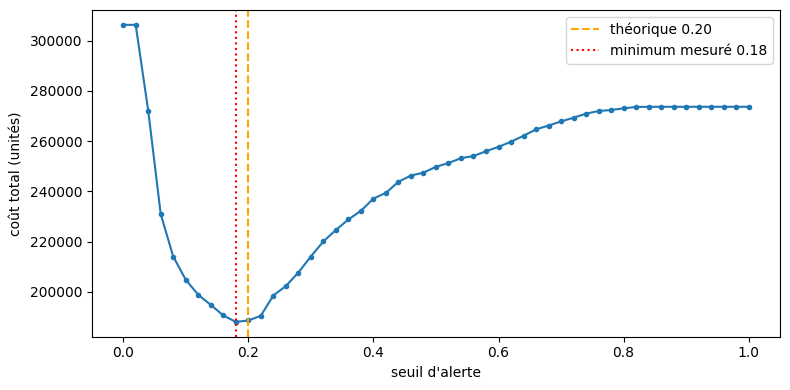

Au seuil 0,50, l'exactitude de l'échantillon personnel vaut 82.49 % (sur toute la validation : 82.51 %), et la facture 249800 unités (FP×25 + FN×100). Le minimum mesuré est 188050 unités au seuil 0.18 : se fier au seuil par défaut coûte 61750 unités de plus, soit 33 % de plus que le minimum ; l'exactitude ne le dit pas, car elle compte chaque erreur pour 1. Le seuil théorique 0.20 coûte 188600 unités ; il est à 0.02 du minimum mesuré, soit au plus la résolution de la grille (0,02) : la formule et la mesure concordent. La formule suppose des probabilités calibrées et des coûts constants (25 par fausse alerte, 100 par absence manquée). Les probabilités sont à peu près calibrées sur cet échantillon (moyenne 0.180 contre un taux réel de 0.183 ; écart maximal par tranche de probabilité : 0.024), donc la formule est raisonnablement applicable ici. Le minimum est cherché et mesuré sur le même échantillon : il est un peu optimiste.
  ok        un seuil écrit entre 0 et 1
  ok        deux coûts

In [82]:
# Le seuil est recherché sur la grille demandée de 0,02 ; les coûts sont comptés sur l'échantillon personnel.
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

seuils_cout = np.round(np.arange(0.0, 1.0001, 0.02), 2)
couts_mesures = [cout(pd.Series((proba_perso > seuil).astype(int), index=yval_perso.index),
                     verite=yval_perso)
                 for seuil in seuils_cout]
indices_interieurs = [i for i, seuil in enumerate(seuils_cout) if 0 < seuil < 1]
indice_optimal = min(indices_interieurs, key=lambda i: couts_mesures[i])
mon_seuil_choisi = float(seuils_cout[indice_optimal])
cout_a_mon_seuil = int(couts_mesures[indice_optimal])
cout_du_seuil_par_defaut = int(cout(
    pd.Series((proba_perso > 0.5).astype(int), index=yval_perso.index), verite=yval_perso))
seuil_theorique_perso = COUT_FP / (COUT_FP + COUT_FN)
cout_theorique_grille = int(couts_mesures[int(np.argmin(np.abs(seuils_cout - seuil_theorique_perso)))])
exactitude_perso_defaut = 100 * np.mean((proba_perso > 0.5).astype(int) == vrai_perso)
exactitude_affichee_validation = 100 * modele.score(Xval, yval)

# la formule suppose des probabilités calibrées : on le vérifie sur l'échantillon personnel
freq_observee, proba_moyenne = calibration_curve(vrai_perso, proba_perso, n_bins=10, strategy="quantile")
ecart_calibration_max = float(np.max(np.abs(freq_observee - proba_moyenne)))
moyenne_proba_perso = float(np.mean(proba_perso))
taux_reel_perso = float(np.mean(vrai_perso))
calibre = ecart_calibration_max <= 0.03 and abs(moyenne_proba_perso - taux_reel_perso) <= 0.01
if calibre:
    phrase_calibration = (f"Les probabilités sont à peu près calibrées sur cet échantillon (moyenne {moyenne_proba_perso:.3f} "
                          f"contre un taux réel de {taux_reel_perso:.3f} ; écart maximal par tranche de probabilité : "
                          f"{ecart_calibration_max:.3f}), donc la formule est raisonnablement applicable ici.")
else:
    phrase_calibration = (f"Les probabilités ne sont pas bien calibrées (moyenne {moyenne_proba_perso:.3f} contre un taux réel "
                          f"de {taux_reel_perso:.3f} ; écart maximal par tranche : {ecart_calibration_max:.3f}) : la formule "
                          "n'est qu'approximative ici.")
distance_seuils = abs(mon_seuil_choisi - seuil_theorique_perso)
if distance_seuils < 0.005:
    phrase_distance = "il coïncide avec le minimum mesuré : la formule et la mesure concordent"
elif distance_seuils <= 0.0201:
    phrase_distance = (f"il est à {distance_seuils:.2f} du minimum mesuré, soit au plus la résolution de la grille (0,02) : "
                       "la formule et la mesure concordent")
else:
    phrase_distance = (f"il est à {distance_seuils:.2f} du minimum mesuré, au-delà de la résolution de la grille (0,02) : "
                       "la formule et la mesure ne concordent pas")
ecart_cout = cout_du_seuil_par_defaut - cout_a_mon_seuil
part_cout = 100 * ecart_cout / cout_a_mon_seuil if cout_a_mon_seuil else float("nan")
ecart_metrique_cout = (
    f"Au seuil 0,50, l'exactitude de l'échantillon personnel vaut {exactitude_perso_defaut:.2f} % (sur toute la validation : "
    f"{exactitude_affichee_validation:.2f} %), et la facture {cout_du_seuil_par_defaut} unités (FP×{COUT_FP} + FN×{COUT_FN}). "
    f"Le minimum mesuré est {cout_a_mon_seuil} unités au seuil {mon_seuil_choisi:.2f} : se fier au seuil par défaut coûte "
    f"{ecart_cout} unités de plus, soit {part_cout:.0f} % de plus que le minimum ; l'exactitude ne le dit pas, car elle compte "
    f"chaque erreur pour 1. Le seuil théorique {seuil_theorique_perso:.2f} coûte {cout_theorique_grille} unités ; "
    f"{phrase_distance}. La formule suppose des probabilités calibrées et des coûts "
    f"constants (25 par fausse alerte, 100 par absence manquée). {phrase_calibration} Le minimum est cherché et mesuré sur le "
    "même échantillon : il est un peu optimiste.")
plt.figure(figsize=(8, 4))
plt.plot(seuils_cout, couts_mesures, marker=".")
plt.axvline(seuil_theorique_perso, color="orange", linestyle="--", label=f"théorique {seuil_theorique_perso:.2f}")
plt.axvline(mon_seuil_choisi, color="red", linestyle=":", label=f"minimum mesuré {mon_seuil_choisi:.2f}")
plt.xlabel("seuil d'alerte")
plt.ylabel("coût total (unités)")
plt.legend()
plt.tight_layout()
plt.show()
print(ecart_metrique_cout)
controle('un seuil écrit entre 0 et 1', lambda: 0 < mon_seuil_choisi < 1, 'un seuil entre 0 et 1')
controle('deux coûts, des entiers positifs',
         lambda: cout_a_mon_seuil >= 0 and cout_du_seuil_par_defaut >= 0
                 and int(cout_a_mon_seuil) == cout_a_mon_seuil,
         'le coût est un entier, en unités de coût')
controle('l’écart est argumenté', lambda: len(ecart_metrique_cout) > 40,
         'chiffrez l’écart, et nommez les deux métriques comparées')

### Question 12 — Les deux classements  ·  *carnet J4*  ·  *cœur*


**Contexte.** Le classement affiché se fait sur l'**exactitude** ; le cours vient de montrer que la décision
se paie en **coût**. Les deux classements ne désignent donc pas la même tête.

**Consigne.**
  1. prenez **deux stratégies** au moins sur votre échantillon (par exemple *n'alerte jamais*, et le
     modèle à deux seuils différents) ;
  2. classez-les deux fois, du meilleur au moins bon : par **exactitude**, puis par **coût** ;
  3. dites si la tête change, et ce que cela coûte de se fier à la métrique affichée.

**Livrables.** `classement_exactitude` · `classement_cout` · `tete_change`.

**Critère de réussite.** Deux stratégies suffisent : ce qui compte est que les deux classements
soient **mesurés sur la même population**.

*≈ 15 min.*


In [83]:
# Trois règles sont comparées sur le même échantillon personnel.
strategies_q12 = {
    "ne jamais alerter": pd.Series(np.zeros(len(vrai_perso), dtype=int), index=yval_perso.index),
    "seuil par défaut 0,50": pd.Series((proba_perso > 0.50).astype(int), index=yval_perso.index),
    f"seuil de coût {mon_seuil_choisi:.2f}": pd.Series(
        (proba_perso > mon_seuil_choisi).astype(int), index=yval_perso.index),
}
mesures_q12 = {}
for nom, decision in strategies_q12.items():
    mesures_q12[nom] = {
        "exactitude (%)": round(100 * np.mean(np.asarray(decision) == vrai_perso), 2),
        "coût": int(cout(decision, verite=yval_perso)),
    }
classement_exactitude = sorted(
    [{"stratégie": nom, **mesure} for nom, mesure in mesures_q12.items()],
    key=lambda ligne: ligne["exactitude (%)"], reverse=True)
classement_cout = sorted(
    [{"stratégie": nom, **mesure} for nom, mesure in mesures_q12.items()],
    key=lambda ligne: ligne["coût"])
tete_exactitude = classement_exactitude[0]["stratégie"]
tete_cout = classement_cout[0]["stratégie"]
tete_change = (
    f"La tête {'change' if tete_exactitude != tete_cout else 'ne change pas'} : l'exactitude place « {tete_exactitude} » en premier, "
    f"mais le coût place « {tete_cout} » en premier. Se fier seulement à l'exactitude choisit une décision qui coûte "
    f"{mesures_q12[tete_exactitude]['coût']} unités contre {mesures_q12[tete_cout]['coût']} unités au meilleur coût.")
display(pd.DataFrame(classement_exactitude))
display(pd.DataFrame(classement_cout))
print(tete_change)
controle('deux classements', lambda: len(classement_exactitude) >= 2 and len(classement_cout) >= 2,
         'deux stratégies au moins, classées deux fois')
controle('la réponse est argumentée', lambda: len(str(tete_change)) > 40,
         'dites si la tête change, et pourquoi')


,stratégie,exactitude (%),coût
0,"seuil par défaut 0,50",82.49,249800
1,ne jamais alerter,81.74,273700
2,seuil de coût 0.18,63.59,188050


,stratégie,exactitude (%),coût
0,seuil de coût 0.18,63.59,188050
1,"seuil par défaut 0,50",82.49,249800
2,ne jamais alerter,81.74,273700


La tête change : l'exactitude place « seuil par défaut 0,50 » en premier, mais le coût place « seuil de coût 0.18 » en premier. Se fier seulement à l'exactitude choisit une décision qui coûte 249800 unités contre 188050 unités au meilleur coût.
  ok        deux classements
  ok        la réponse est argumentée


## Ce qu’on rend, et pourquoi ce format

**Trois tableaux**, comme au devoir 1 :

- **le tableau à quatre colonnes** — modèle · validation · affiché · écart — et vos trois phrases ;
- **le journal de nettoyage** — une ligne par décision : la décision, le choix fait, l’effet mesuré ;
- **le tableau d’essais** — une ligne par changement, avec l’attendu (un signe et une raison) et le
  mesuré.

Les **constats chiffrés** et les **hypothèses de features** appartiennent au **devoir 1**. Les
questions d’ici portent sur les baselines, le nettoyage et la mesure. Les tableaux qui les
portent sont ceux-ci. **Vos métriques, vos aires et votre seuil** (Q10, Q11) se lisent dans les cellules qui
les produisent.

La cellule qui suit affiche **les trois tableaux** remplis automatiquement, tels que vous les rendez.


In [84]:
print("vos essais \n")
display(pd.DataFrame(ESSAIS))
print("votre journal de nettoyage \n")
display(pd.DataFrame(JOURNAL))
print("votre tableau à quatre colonnes \n")
try:
    tableau_quatre_colonnes = mon_tableau
except NameError:
    tableau_quatre_colonnes = pd.DataFrame()
display(tableau_quatre_colonnes)
print("vos contrôles \n")
display(pd.DataFrame(VERIFICATIONS))


vos essais 



,hypothèse,changement,attendu,mesuré,prédiction écrite avant ?
0,"Q2 · max_iter=20, max_leaf_nodes=7","max_iter=20, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,83.20,"oui, à 22:33:36"
1,"Q2 · max_iter=40, max_leaf_nodes=7","max_iter=40, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,83.20,"oui, à 22:33:36"
2,"Q2 · max_iter=60, max_leaf_nodes=7","max_iter=60, max_leaf_nodes=7",Je prévois que le meilleur réglage sur les 1 0...,83.20,"oui, à 22:33:36"
3,"Q2 · max_iter=20, max_leaf_nodes=15","max_iter=20, max_leaf_nodes=15",Je prévois que le meilleur réglage sur les 1 0...,83.00,"oui, à 22:33:36"
4,"Q2 · max_iter=40, max_leaf_nodes=15","max_iter=40, max_leaf_nodes=15",Je prévois que le meilleur réglage sur les 1 0...,82.90,"oui, à 22:33:36"
5,"Q2 · max_iter=60, max_leaf_nodes=15","max_iter=60, max_leaf_nodes=15",Je prévois que le meilleur réglage sur les 1 0...,82.80,"oui, à 22:33:36"
6,Q5 · HistGradientBoosting,famille HistGradientBoosting,Je prévois que les trois familles auront des e...,82.51,"oui, à 22:33:47"
7,Q5 · LogisticRegression,famille LogisticRegression,Je prévois que les trois familles auront des e...,82.21,"oui, à 22:33:47"
8,Q5 · RandomForest,famille RandomForest,Je prévois que les trois familles auront des e...,82.32,"oui, à 22:33:47"


votre journal de nettoyage 



,décision,choix,raison (sans le score),effet mesuré,> double de la barre ?
0,un trou aléatoire,solde_credit laissé tel quel (contre : comblé ...,les taux d'absence sont proches quand solde_cr...,0.08,non
1,un trou structurel,constantes_relevees écartée (contre : la garder),constantes_relevees décrit une mesure prise pe...,-0.72,oui
2,des colonnes inutiles,écartées (contre : les garder),zone_clinique n'a qu'une seule valeur sur tout...,0.01,non
3,un code non documenté,code_assurance conservé en attendant sa docume...,le dictionnaire ne définit pas les codes 7 et ...,0.01,non
4,une valeur impossible,46 ligne(s) avec age = -1 retirée(s) de l'appr...,un âge de -1 est une valeur sentinelle impossi...,-0.00,non
5,des lignes dupliquées,0 doublon(s) trouvé(s) ; aucune ligne à retirer,un doublon est la même observation répétée une...,0.00,non


votre tableau à quatre colonnes 



,modèle,validation,affiché,écart
0,modèle du cours,82.51,81.81,-0.7
1,réponse constante,81.75,NaN,NaN
2,régression logistique,82.21,NaN,NaN


vos contrôles 



,contrôle,tient
0,les données sont chargées,True
1,la table de travail est construite,True
2,"le découpage est fait, le modèle ajusté",True
3,les baselines sont mesurées,True
4,votre échantillon personnel est prêt,True
5,le pipeline tourne sur une table brute,True
6,le fichier est écrit,True
7,la règle est écrite,True
8,une exactitude en pourcentage,True
9,un écart exprimé en erreurs-types,True


## Rendre le travail

1. **Exécutez tout** le carnet (`Run All`), pour que les tableaux soient remplis.
2. **Déposez** ce carnet dans votre dépôt GitHub personnel. Mettez **avec** lui votre déclaration d’usage de
   l’IA, dans le **même commit** :
   - téléchargez le modèle **`DECLARATION_modele.md`** depuis le **dépôt du cours** ;
   - recopiez-le dans votre dépôt sous le nom **`declaration_DM2.md`** ;
   - remplissez-le : les deux scores, ce que vous avez produit seul, ce que vous avez fait
     avec un assistant, et ce que vous ne sauriez pas expliquer.
3. Vérifiez que le lien de votre dépôt est bien à jour dans le formulaire de la classe.

> Un travail non déposé n’existe pas.
